# Oil-palm zoning and VARI analysis

This notebook processes a WebODM RGB image into tree detections, zones, VARI summaries, fertilizer calculations, and output images/files.

Run the notebook **from top to bottom**. Set the image/model paths and calculation settings in the configuration cell first. Generated images, JSON/CSV files, and zone-crop folders are saved under `outputs/`. Each numbered section below has its own code cell so you can follow the pipeline stage by stage.

## Imports

In [65]:
import csv
import json
import math
import html
from pathlib import Path
import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import matplotlib.cm as cm
import matplotlib.colors as mcolors

from IPython.display import display, HTML


## Configuration

Edit the input paths, output paths, detection settings, zoning rules, and fertilizer settings here.

In [66]:
# ------------------------- Configuration -------------------------
# All generated files (images, tables, JSON, and crop folders) go here.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_PATH = "webodm_new_2nd_flight.jpeg"  # Input RGB image to segment, detect palms, calculate VARI, and zone.
# IMAGE_PATH = "webodm_last_image_1st_flight.jpeg"
MODEL_PATH = "krops_model_v0.2_yolo26l.mlpackage"  # CoreML object-detection model used to detect palm trees.
# MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"  # CoreML object-detection model used to detect palm trees.
OUTPUT_JSON = str(OUTPUT_DIR / "oil_palm_zones_vari.json")  # JSON with metadata, zone/tree statistics, and recommendations.

# UI submission input: this file represents the fields entered in the farm/profile screens.
USER_SUBMISSION_JSON_PATH = Path.cwd() / "user_submission_request.json"
with open(USER_SUBMISSION_JSON_PATH, "r", encoding="utf-8") as _ui_input_file:
    UI_SUBMISSION_DATA = json.load(_ui_input_file)
UI_FARM_INPUT = UI_SUBMISSION_DATA.get("farm", {})

# Screen-entered values are loaded from the submission JSON; image/map fields remain optional.
PULSE_CHECK_FARM_PROFILE = {
    "name": UI_FARM_INPUT.get("name"),
    "location_label": UI_FARM_INPUT.get("location_label"),
    "area_ha": UI_FARM_INPUT.get("areaHa"),
    "perimeter_m": UI_FARM_INPUT.get("perimeterM"),
    "planting_year": UI_FARM_INPUT.get("year"),
    "soil_type": UI_FARM_INPUT.get("soil"),
    "farm_boundary_geojson": UI_FARM_INPUT.get("farmBoundaryGeojson"),
    "review_month": UI_SUBMISSION_DATA.get("month"),
}
PULSE_CHECK_ZONE_BOUNDARIES_GEOJSON = {}  # Optional {"Z1": GeoJSON geometry, ...}; image bboxes are not map polygons.
PULSE_CHECK_NUTRIENT_MEASUREMENTS = None  # Optional measured soil/leaf results; not part of the current screens.
PULSE_CHECK_FERTILIZER_HISTORY = UI_SUBMISSION_DATA.get("fertilizerHistory")
PULSE_CHECK_HARVEST_HISTORY = UI_SUBMISSION_DATA.get("harvest")
PULSE_CHECK_ZONE_APPLICATION_STATUS = {}  # Optional {"Z1": {"status": "done", "completed_at": ...}, ...}.
OUTPUT_ZONE_CSV = str(OUTPUT_DIR / "oil_palm_zone_vari_summary.csv")  # CSV with one row per zone and its VARI/fertilizer values.
OUTPUT_PRODUCT_MASS_CSV = str(OUTPUT_DIR / "oil_palm_zone_fertilizer_product_mass.csv")  # CSV converting elemental nutrient totals to product mass.
OUTPUT_EXG_MASK = str(OUTPUT_DIR / "oil_palm_exg_mask.png")  # Binary vegetation mask produced by ExG thresholding.
OUTPUT_EXG_SEGMENTED = str(OUTPUT_DIR / "oil_palm_exg_segmented.jpg")  # RGB image showing pixels retained by the ExG vegetation mask.
OUTPUT_COREML_ANNOTATED = str(OUTPUT_DIR / "oil_palm_coreml_detections.jpg")  # ExG-segmented image with detected palm boxes and labels.
OUTPUT_ZONE_ANNOTATED = str(OUTPUT_DIR / "oil_palm_zones_only.jpg")  # Black background with detected tree pixels colored by zone.
OUTPUT_ANNOTATED_IMAGE = str(OUTPUT_DIR / "oil_palm_zones_annotated.jpg")  # Original image with zone colors, tree labels, and boost overlays.
OUTPUT_WHITE_ZONE_ANNOTATED = str(OUTPUT_DIR / "oil_palm_zones_white_separators.jpg")  # Original image with white zone boundaries and no zone-color fill.
WHITE_ZONE_BOUNDARY_WIDTH_PX = 9  # Thickness of the white-only shared zone boundaries in the separator image.
OUTPUT_ZONE_BASE_CROPS_DIR = str(OUTPUT_DIR / "oil_palm_zone_base_crops")  # Folder for original-image crops, one per zone.
OUTPUT_ZONE_EXG_CROPS_DIR = str(OUTPUT_DIR / "oil_palm_zone_exg_crops")  # Folder for ExG-segmented image crops, one per zone.
OUTPUT_PIPELINE_PLOT = str(OUTPUT_DIR / "oil_palm_pipeline_stages.jpg")  # Combined visualization of the analysis pipeline outputs.
OUTPUT_VARI_DISTRIBUTION = str(OUTPUT_DIR / "oil_palm_vari_distribution.png")  # Zone mean VARI values with the P25–P95 range highlighted.
CONF_THRESHOLD = 0.10  # Temporary recall-focused cutoff; inspect lower-confidence detections for false positives.
IOU_THRESHOLD = 0.45  # Non-maximum suppression overlap threshold for removing duplicate detections.
MODEL_INPUT_SIZE = 640  # Width and height, in pixels, of the square image passed to the CoreML model.
ZONE_GRID_ROWS = 3  # Target number of palm rows grouped into one zone band.
ZONE_GRID_COLS = 3  # Target number of palms per row within a zone; nominal capacity is rows × columns.
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS  # Nominal tree capacity used to mark zones as undersized.
MIN_TREES_TO_KEEP_ZONE = 2  # Merge a one-tree spatial zone into a directly adjacent zone when possible.
ROW_TOLERANCE_MULTIPLIER = 0.75  # Same-row center tolerance as a fraction of median detected tree height.
MAX_ZONE_DISTANCE_MULTIPLIER = 3.0  # Maximum row/column grouping gap as a fraction of median tree height.
ZONE_PADDING_MULTIPLIER = 0.15  # Padding around each zone bounding box as a fraction of median tree height.
MIN_TREE_COMPLETENESS = 0.70  # Keep a detection only if its width, height, and area are each >=70% of their medians.
MAX_TREE_DIMENSION_MULTIPLIER = 4.0  # Reject extreme boxes wider or taller than 4× the robust typical tree box.
MAX_TREE_AREA_MULTIPLIER = 20.0  # Reject extreme boxes with area greater than 20× the robust typical tree-box area.
BORDER_MARGIN_PX = 5  # Exclude detections whose bounding boxes come within 5 pixels of any image edge.
SHOW_PLOTS = True  # Display the generated pipeline figure interactively after saving it.
# If the spread between zone-mean VARI P95 and P25 is at or below this
# configured absolute VARI gap, use the P25-derived boost across all zones.
# Tune this threshold for the imagery and management policy; set to 0.0 to
# effectively disable the blanket mode for a nonzero spread.
MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST = 0.03
# Maximum annual elemental Mg and N nutrient rates per hectare/year, supplied
# by the user. These are nutrient quantities, independent of product choice.
# Zone targets are B_i × the corresponding nutrient rate.
MAX_NUTRIENT_KG_HA_PER_YEAR = {
    "Mg": 13.0,
    "N": 90.0,
}
FERTILIZER_NUTRIENT_BY_PRODUCT = {
    "kieserite_Mg_expensive": "Mg", "dolomite_Mg_cheaper": "Mg",
    "ZA_N_cheaper": "N", "urea_N_expensive": "N",
}
# Product label fractions in the form printed on the bag. Mg fertilizers use
# MgO labels; N fertilizers use elemental N labels. Set each product guarantee
# here once. Product kg is calculated in two steps: nutrient -> label basis -> product.
FERTILIZER_PRODUCT_LABEL_FRACTIONS = {
    "kieserite_Mg_expensive": {"basis": "MgO", "fraction": 0.255},
    "dolomite_Mg_cheaper": {"basis": "MgO", "fraction": 0.22},
    "ZA_N_cheaper": {"basis": "N", "fraction": 0.21},
    "urea_N_expensive": {"basis": "N", "fraction": 0.46},
}
MGO_TO_MG_FACTOR = 24.305 / 40.304  # Elemental Mg mass contained in one unit of MgO mass.
MG_TO_MGO_FACTOR = 40.304 / 24.305  # MgO mass equivalent to one unit of elemental Mg mass.
# Derived elemental nutrient per kg product fractions. These are calculated
# from the single label configuration above and should not be edited separately.
FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS = {
    product: config["fraction"] * (MGO_TO_MG_FACTOR if config["basis"] == "MgO" else 1.0)
    for product, config in FERTILIZER_PRODUCT_LABEL_FRACTIONS.items()
}
# Annual base product rates, kept separate from VARI-derived supplements.
# Each Mg product defaults to 1.0 kg/palm/year. If the user entered that product,
# use dosePerTree × fertilizer-history frequency/year instead of its default.
_ui_history = PULSE_CHECK_FERTILIZER_HISTORY or {}
_ui_history_freq_value = _ui_history.get("freq")
_ui_history_freq_per_year = float(1 if _ui_history_freq_value is None else _ui_history_freq_value)
_ui_history_products = _ui_history.get("fertilizers", [])

def _base_product_rate_from_history(product_names, default_rate=1.0):
    aliases = {name.casefold() for name in product_names}
    entries = [item for item in _ui_history_products
               if str(item.get("name", "")).strip().casefold() in aliases
               and item.get("dosePerTree") is not None]
    if not entries:
        return float(default_rate), "default: 1.0 kg/palm/year (no entered product dose)"
    annual_rate = sum(float(item["dosePerTree"]) * _ui_history_freq_per_year for item in entries)
    dose_terms = " + ".join(f"{float(item['dosePerTree']):g} × {_ui_history_freq_per_year:g}"
                             for item in entries)
    return annual_rate, f"from UI history: ({dose_terms}) kg/palm/year"

KIESERITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR, KIESERITE_BASE_RATE_SOURCE = (
    _base_product_rate_from_history(("kieserite", "kieserit"))
)
DOLOMITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR, DOLOMITE_BASE_RATE_SOURCE = (
    _base_product_rate_from_history(("dolomite", "dolomit"))
)
ZA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
UREA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = None
FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR = {
    "kieserite_Mg_expensive": KIESERITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "dolomite_Mg_cheaper": DOLOMITE_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "ZA_N_cheaper": ZA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
    "urea_N_expensive": UREA_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
}
# Optional costs are in a user-selected currency per kg of fertilizer product.
# Leave empty (or omit a product) to suppress cost outputs.
FERTILIZER_PRICE_PER_KG = {}
# Provide ground area per zone in hectares. Either use a JSON file such as
# {"1": 0.25, "2": 0.30}, or a uniform hectare value for every zone.
# If neither is supplied, TOTAL_FARM_AREA_HA is split across zones by detected
# tree count. Set it to 2.0 to double area-based totals relative to 1.0 ha.
ZONE_AREA_HA_BY_ID = {}
ZONE_AREA_JSON_PATH = None
UNIFORM_ZONE_AREA_HA = None  # Optional override applied to every zone
TOTAL_FARM_AREA_HA = float(UI_FARM_INPUT.get("areaHa") or 1.0)  # Use the farm area entered in the profile JSON; default to 1 ha if blank.
# Default approximation from palm spacing. Midpoint of the supplied 9–11 m
# gap is 10 m, or 0.01 ha per palm. Zone area scales with detected tree count.
DEFAULT_TREE_SPACING_M = 10.0
USE_SPACING_BASED_ZONE_AREA_DEFAULT = True
# Optional manual final-confidence overrides by zone ID; leave empty to use the
# confidence calculation below. Each configured value must be in [0.10, 1.0].
ZONE_CONFIDENCE_BY_ID = {}
# Flight-level confidence (L6), when assessed. Until it is assessed, the
# default below stands in as the flight factor and the run/each zone is flagged.
FLIGHT_CONFIDENCE = None
DEFAULT_ZONE_CONFIDENCE = 0.60
# Notebook confidence model (team proposal, values marked GUESS until calibrated).
ZONE_CONFIDENCE_FULL_TREES = 9  # Tree factor reaches 1.0 at this many palms.
ZONE_LEAF_PIXEL_FULL_RATIO = 0.70  # Leaf factor reaches 1.0 at this zone/photo leaf-pixel ratio.
ZONE_REFERENCE_MIN_FACTOR = 0.70  # Zones below this zone factor do not set P25/P95.
ZONE_CONFIDENCE_FLOOR = 0.10  # Keep nonzero boost confidence at or above this floor.
MIN_REFERENCE_ZONES_SUGGESTED = 5  # Emit a metadata note when fewer valid reference zones qualify.
# -----------------------------------------------------------------


## Shared analysis functions

These helper functions handle detections, tree filtering, zoning, and pixel-coordinate records.

In [67]:
def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.
    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)
    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )
    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)
    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
    ):
    """Group detected palms by approximate row bands and fixed spatial column blocks."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")
    if not trees:
        return []
    target_trees_per_zone = grid_rows * grid_cols
# 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))
    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))
# 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []
    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")
        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance
        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)
    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])
# 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []
    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)
    if current_band:
        row_bands.append(current_band)
# 4. Within each row band, assign trees to fixed spatial column blocks.
# Missing detections leave empty positions instead of shifting later trees.
    zones = []
    row_gaps = []
    for row in rows:
        row_x = sorted(float(tree["center"][0]) for tree in row)
        row_gaps.extend(
            gap for gap in np.diff(row_x)
            if gap > 0 and gap <= max_zone_distance
        )
    typical_column_spacing = float(np.median(row_gaps)) if row_gaps else max(1.0, median_height * 2.0)
    global_x_origin = min(float(tree["center"][0]) for tree in trees)
    spatial_block_width = max(1.0, typical_column_spacing * grid_cols)
    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
# Assign by fixed x intervals, not by chunks or gaps in detected-tree counts.
        spatial_blocks = {}
        for tree in band_trees:
            block_id = int(np.floor((tree["center"][0] - global_x_origin) / spatial_block_width))
            spatial_blocks.setdefault(block_id, []).append(tree)
        for block_id in sorted(spatial_blocks):
            members = spatial_blocks[block_id]
            x1 = min(t["bbox"][0] for t in members) - padding
            y1 = min(t["bbox"][1] for t in members) - padding
            x2 = max(t["bbox"][2] for t in members) + padding
            y2 = max(t["bbox"][3] for t in members) + padding
            if image_width is not None:
                x1 = max(0, x1)
                x2 = min(image_width, x2)
            if image_height is not None:
                y1 = max(0, y1)
                y2 = min(image_height, y2)
            zones.append({
                "zone_id": len(zones) + 1,
                "approx_row": band_idx,
                "spatial_column_block": block_id,
                "trees": members,
                "bbox": [x1, y1, x2, y2],
                "is_undersized": len(members) < target_trees_per_zone,
            })
    return zones


def merge_small_adjacent_zones(zones, min_tree_count=MIN_TREES_TO_KEEP_ZONE):
    """Merge undersized zones into the nearest zone in an adjacent grid cell."""
    zones = list(zones)
    for source in sorted(zones, key=lambda item: (len(item["trees"]), item["zone_id"])):
        if source not in zones or len(source["trees"]) >= min_tree_count:
            continue
        source_row = source.get("approx_row")
        source_col = source.get("spatial_column_block")
        source_center = np.mean([tree["center"] for tree in source["trees"]], axis=0)
        candidates = []
        for target in zones:
            if target is source:
                continue
            row_delta = abs(target.get("approx_row", source_row) - source_row)
            col_delta = abs(target.get("spatial_column_block", source_col) - source_col)
            if row_delta <= 1 and col_delta <= 1:
                target_center = np.mean([tree["center"] for tree in target["trees"]], axis=0)
                distance = float(np.linalg.norm(source_center - target_center))
                candidates.append((distance, target))
        if not candidates:
            continue
        _, target = min(candidates, key=lambda item: item[0])
        target["trees"].extend(source["trees"])
        target["bbox"] = [
            min(target["bbox"][0], source["bbox"][0]),
            min(target["bbox"][1], source["bbox"][1]),
            max(target["bbox"][2], source["bbox"][2]),
            max(target["bbox"][3], source["bbox"][3]),
        ]
        target.setdefault("merged_from_zone_ids", []).extend(
            source.get("merged_from_zone_ids", [source["zone_id"]])
        )
        zones.remove(source)
    zones.sort(key=lambda item: (item.get("approx_row", 0), item.get("spatial_column_block", 0)))
    for new_zone_id, zone in enumerate(zones, start=1):
        zone["zone_id"] = new_zone_id
        zone["is_undersized"] = len(zone["trees"]) < TREES_PER_ZONE
    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def show_preview_table(title, headers, rows):
    """Render a compact HTML table so intermediate records are readable in Jupyter."""
    header_html = "".join(f"<th>{html.escape(str(value))}</th>" for value in headers)
    body_html = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(
        f"<h4>{html.escape(str(title))}</h4>"
        f"<div style='overflow-x:auto'><table style='border-collapse:collapse;font-size:13px;white-space:nowrap'>"
        f"<thead><tr style='background:#263238;color:white'>{header_html}</tr></thead>"
        f"<tbody>{body_html}</tbody></table></div>"
    ))


## Zone summary and nutrient calculations

Functions for the annual zone table and its detailed nutrient calculation output.

In [68]:
def print_zone_vari_table(zone_json):
    """Print annual VARI-derived elemental nutrient supplements by zone."""
    nutrients = [nutrient for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items() if rate is not None]
    headers = ["Zone", "Trees", "Mean VARI", "Min VARI", "Min VARI review",
               "Zone factor", "Zone confidence", "Overall field confidence (applied)",
               "Qualifies for P25/P95?", "Raw zone boost", "Boost mode / basis",
               *[f"Additional {nutrient} boost only" for nutrient in nutrients]]
    valid_means = [float(z["vari"]["mean_vari"]) for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    rows = []
    def fmt(value, digits=3):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        boost = rec.get("boost_fraction")
        mean = zone.get("vari", {}).get("mean_vari")
        if boost is None:
            boost_mode_text = "Unavailable"
        elif rec.get("boost_mode") == "blanket_p25":
            boost_mode_text = f"Blanket (P25={rec.get('p25_zone_mean_vari'):.3f}): {100 * boost:.1f}%"
        else:
            boost_mode_text = f"Zone-specific: {100 * boost:.1f}%"
        row = [f"Z{zone['zone_id']}", fmt(zone.get("tree_count")),
               fmt(mean),
               fmt(zone.get("vari", {}).get("min_vari")),
               ("CHECK: lowest zone min" if zone.get("vari", {}).get("lowest_min_vari_zone") else "—"),
               fmt(zone.get("confidence", {}).get("zone_factor"), digits=4),
               fmt(zone.get("confidence", {}).get("confidence"), digits=4),
               fmt(rec.get("overall_field_confidence"), digits=4),
               ("yes" if zone.get("confidence", {}).get("reference_zone") else "no"),
               (f"{100 * rec['zone_specific_boost_fraction']:.1f}%" if rec.get("zone_specific_boost_fraction") is not None else "N/A"),
               boost_mode_text]
        for nutrient in nutrients:
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product, {}) if product is not None else {}
            total = item.get("annual_total_kg")
            per_palm = item.get("kg_per_palm_per_year")
            row.append(f"{fmt(total, digits=4)} kg/zone/year; "
                       f"{fmt(per_palm, digits=4)} kg/palm/year")
        rows.append(row)
    widths = [max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
              for i, header in enumerate(headers)]
    print("\n--- Zone VARI-Derived Nutrient Supplement Summary (annual) ---")
    overall_field_confidence = (zone_json[0].get("recommendation", {}).get("overall_field_confidence")
                                if zone_json else None)
    print("Notebook confidence thresholds are proposals/guesses pending calibration against field observations.")
    print("Min VARI review flags every zone tied for the lowest valid zone minimum; it is a screening flag for follow-up, not a diagnosis.")
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))
    print("\nConfidence calculations (section 5b):")
    if zone_json:
        first_confidence = zone_json[0].get("confidence", {})
        median_leaf_px = first_confidence.get("median_leaf_pixels_per_tree", 0.0)
        for zone in zone_json:
            c = zone.get("confidence", {})
            n = max(0, int(zone.get("tree_count", 0)))
            leaf_px = int(c.get("leaf_pixel_count", zone.get("vari", {}).get("vegetation_pixel_count", 0)) or 0)
            tree_factor = float(c.get("tree_factor", 0.0))
            leaf_ratio = float(c.get("leaf_pixel_ratio", 0.0))
            leaf_factor = float(c.get("leaf_pixel_factor", 0.0))
            zone_factor = float(c.get("zone_factor", 0.0))
            local_confidence = float(c.get("confidence", 0.0))
            flight = float(c.get("flight_confidence", 0.0))
            print(f"  Z{zone['zone_id']} (weight = {n} trees):")
            print(f"    Tree factor = min(1, sqrt({n} ÷ {ZONE_CONFIDENCE_FULL_TREES})) = {tree_factor:.4f}")
            if n > 0 and median_leaf_px:
                print(f"    Leaf ratio = {leaf_px} ÷ ({n} × {median_leaf_px:.2f} median leaf pixels/tree) = {leaf_ratio:.4f}")
            else:
                print(f"    Leaf ratio = 0.0000 (no valid tree/leaf-pixel denominator)")
            print(f"    Leaf factor = min(1, {leaf_ratio:.4f} ÷ {ZONE_LEAF_PIXEL_FULL_RATIO:.4f}) = {leaf_factor:.4f}")
            print(f"    Zone factor = {tree_factor:.4f} × {leaf_factor:.4f} = {zone_factor:.4f}")
            if c.get("manual_override") is not None:
                print(f"    Zone confidence = manual override {local_confidence:.4f}")
            else:
                print(f"    Zone confidence = clamp({flight:.4f} flight × {zone_factor:.4f} zone factor, "
                      f"{ZONE_CONFIDENCE_FLOOR:.2f}, 1.00) = {local_confidence:.4f}")
        overall_raw = first_confidence.get("overall_field_confidence_raw")
        total_weight = sum(max(0, int(z.get("tree_count", 0))) for z in zone_json)
        weighted_terms = " + ".join(
            f"({z.get('confidence', {}).get('confidence', 0.0):.4f} × "
            f"{max(0, int(z.get('tree_count', 0)))})" for z in zone_json
        )
        print("  Overall field confidence = tree-count-weighted mean of zone confidences:")
        if overall_raw is not None and total_weight > 0:
            print(f"    ({weighted_terms}) ÷ {total_weight} total trees = {overall_raw:.6f}")
            print(f"    Clamp to [{ZONE_CONFIDENCE_FLOOR:.2f}, 1.00] = {overall_field_confidence:.4f}")
        else:
            print(f"    No detected trees; use confidence floor {ZONE_CONFIDENCE_FLOOR:.2f}")
        print("    This one overall value is used in every zone's boost calculation.")
    print("\nBoost calculation by zone:")
    print("  Vref = 95th percentile of valid zone mean VARI values from reference zones only")
    first_rec = zone_json[0].get("recommendation", {}) if zone_json else {}
    boost_mode = first_rec.get("boost_mode", "zone_specific")
    p25 = first_rec.get("p25_zone_mean_vari")
    p95 = first_rec.get("reference_zone_mean_vari")
    gap = first_rec.get("p95_p25_vari_gap")
    reference_id_set = {str(value) for value in first_rec.get("reference_zone_ids", [])}
    reference_means = [float(z["vari"]["mean_vari"]) for z in zone_json
                       if str(z.get("zone_id")) in reference_id_set
                       and z.get("vari", {}).get("mean_vari") is not None
                       and np.isfinite(z["vari"]["mean_vari"])]
    if first_rec.get("reference_fallback_all_zones"):
        reference_means = valid_means
    sorted_means = sorted(reference_means)
    print("  Reference zone IDs = " + (", ".join(f"Z{zid}" for zid in first_rec.get("reference_zone_ids", [])) or "none"))
    if first_rec.get("reference_fallback_all_zones"):
        print("  No zones qualified, so P25/P95 fall back to all valid zone means.")
    for flag in first_rec.get("zone_confidence_run_flags", []):
        print(f"  Confidence note: {flag}")
    print("  Sorted reference-zone mean VARI values = " + ", ".join(f"{value:.3f}" for value in sorted_means))
    print("  Sorted values use zero-based indexes: " + ", ".join(f"sorted[{i}]={value:.6f}" for i, value in enumerate(sorted_means)))
    if p25 is not None and p95 is not None:
        print(f"  Quantile references (linear interpolation): P25={p25:.3f}; P95={p95:.3f}")
        def print_quantile_steps(label, percentile):
            if not sorted_means:
                return
            position = (len(sorted_means) - 1) * percentile
            lower_index = int(np.floor(position))
            upper_index = int(np.ceil(position))
            fraction = position - lower_index
            lower_value = sorted_means[lower_index]
            upper_value = sorted_means[upper_index]
            result = lower_value + fraction * (upper_value - lower_value)
            if lower_index == upper_index:
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"sorted[{lower_index}]={lower_value:.6f}")
            else:
                lower_weight = 1.0 - fraction
                lower_part = lower_weight * lower_value
                upper_part = fraction * upper_value
                print(f"  {label}: position=({len(sorted_means)}-1)×{percentile:.2f}={position:.2f}; "
                      f"interpolate sorted[{lower_index}]={lower_value:.6f} and "
                      f"sorted[{upper_index}]={upper_value:.6f} with fraction {fraction:.2f}: "
                      f"({lower_weight:.2f}×{lower_value:.6f})+({fraction:.2f}×{upper_value:.6f}) "
                      f"={lower_part:.6f}+{upper_part:.6f}={result:.6f}")
        print_quantile_steps("P25 calculation", 0.25)
        print_quantile_steps("P95 calculation", 0.95)
    print(f"  P95-P25 zone-mean VARI gap = {gap:.3f}" if gap is not None else "  P95-P25 zone-mean VARI gap unavailable")
    print(f"  Boost mode = {boost_mode}; blanket cutoff = {MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST:.3f}")
    print("  B_i = max(0, 1 - V_input / Vref) × overall field confidence")
    if boost_mode == "blanket_p25" and p25 is not None:
        print(f"  Blanket mode uses V_input=P25={p25:.3f} for every zone")
    else:
        print("  Zone-specific mode uses each zone's own mean VARI as V_input")
    print("  Annual zone supplement = B_i × whole-farm nutrient amount × zone area share")
    print("  These are additional VARI-scaled Mg/N quantities, not the full annual fertilizer program.")
    effective_area = sum(
        zone.get("recommendation", {}).get("zone_area_ha") or 0.0 for zone in zone_json
    )
    print(f"  Sum of zone areas used in these totals = {effective_area:.4f} ha")
    farm_rate_totals = {
        nutrient: float(rate) * effective_area
        for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items()
        if rate is not None
    }
    if farm_rate_totals:
        print("  Full-rate reference for this area (before VARI boost): " + "; ".join(
            f"{nutrient} = {float(MAX_NUTRIENT_KG_HA_PER_YEAR[nutrient]):.3f} kg/ha/year × "
            f"{effective_area:.4f} ha = {total:.3f} kg/year"
            for nutrient, total in farm_rate_totals.items()
        ))
    print("Detailed additional Mg and N calculations by zone:")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        mean = zone.get("vari", {}).get("mean_vari")
        reference = rec.get("reference_zone_mean_vari")
        deficit = rec.get("vari_deficit_fraction")
        confidence = rec.get("zone_confidence")
        boost = rec.get("boost_fraction")
        if None in (mean, reference, deficit, confidence, boost) or reference <= 0:
            print(f"  Z{zone['zone_id']}: cannot calculate (missing/invalid VARI reference or zone mean)")
        else:
            boost_input = rec.get("boost_vari_input", mean)
            print(f"  Z{zone['zone_id']}: zone mean VARI={mean:.9f}; V_input={boost_input:.9f}; Vref(P95)={reference:.9f}; "
                  f"B_i=max(0, 1 - {boost_input:.9f}/{reference:.9f}) × {confidence:.6f}="
                  f"{boost:.9f} ({boost * 100:.6f}%)")
        for nutrient, max_rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
            product = next((name for name, mapped_nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items()
                            if mapped_nutrient == nutrient and name in rec.get("fertilizers", {})), None)
            item = rec.get("fertilizers", {}).get(product) if product is not None else None
            if not item:
                continue
            if boost is None:
                print(f"    {nutrient}: unavailable because zone boost could not be calculated")
                continue
            zone_total = item["annual_total_kg"]
            per_palm = item["kg_per_palm_per_year"]
            area = rec.get("zone_area_ha")
            zone_text = f"{zone_total:.6f}" if zone_total is not None else "N/A"
            per_palm_text = f"{per_palm:.6f}" if per_palm is not None else "N/A"
            area_text = f"{area:.6f}" if area is not None else "N/A"
            tree_count = zone.get("tree_count", 0)
            if area is not None and effective_area > 0:
                farm_total = float(max_rate) * effective_area
                zone_share = float(area) / effective_area
                print(f"      additional {nutrient} supplement/zone/year = B_i × whole-farm {nutrient} amount × zone area share = "
                      f"{boost:.9f} × {farm_total:.3f} kg {nutrient}/farm/year × "
                      f"({area_text} ha ÷ {effective_area:.4f} ha = {zone_share:.6f}) = "
                      f"{zone_text} kg {nutrient}/zone/year")
                print(f"        equivalent per-hectare form: {boost:.9f} × {max_rate:.3f} kg {nutrient}/ha/year × "
                      f"{area_text} ha = {zone_text} kg {nutrient}/zone/year")
            else:
                print(f"      additional {nutrient} supplement/zone/year = N/A (zone area is unavailable)")
            print(f"      per palm = {zone_text} kg ÷ {tree_count} trees = "
                  f"{per_palm_text} kg {nutrient}/palm/year")
    print("Values above are additional annual elemental Mg or N supplements, not full product rates or full fertilizer-program totals.")


## CSV and fertilizer product-mass outputs

In [69]:
def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI and fertilizer recommendation fields."""
    fieldnames = ["zone_id", "approx_row", "tree_count", "bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2",
                  "vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                  "lowest_min_vari_zone", "lowest_zone_min_vari_value", "min_vari_review_note",
                  "tree_factor", "leaf_pixel_count", "median_leaf_pixels_per_tree", "leaf_pixel_ratio",
                  "leaf_pixel_factor", "zone_factor", "flight_confidence", "flight_confidence_source",
                  "calculated_zone_confidence", "overall_field_confidence_raw", "overall_field_confidence",
                  "confidence_used_for_boost", "field_confidence_weight", "manual_zone_confidence_override", "zone_is_reference",
                  "confidence_flags",
                  "reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                  "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input", "zone_confidence",
                  "zone_local_confidence",
                  "zone_specific_vari_deficit_fraction", "zone_specific_boost_fraction",
                  "vari_deficit_fraction", "boost_fraction", "zone_area_ha"]
    metrics = ("boost_added_rate_kg_ha_per_year", "boosted_rate_kg_ha_per_year",
               "annual_total_kg", "kg_per_palm_per_year")
    fieldnames += [f"{product}_{metric}" for product in FERTILIZER_NUTRIENT_BY_PRODUCT for metric in metrics]
    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox, stats = zone.get("bbox", {}), zone.get("vari", {})
            confidence = zone.get("confidence", {})
            rec = zone.get("recommendation", {})
            row = {"zone_id": zone.get("zone_id"), "approx_row": zone.get("approx_row"),
                   "tree_count": zone.get("tree_count"), "bbox_x1": bbox.get("x1"), "bbox_y1": bbox.get("y1"),
                   "bbox_x2": bbox.get("x2"), "bbox_y2": bbox.get("y2"),
                   **{k: stats.get(k) for k in ("vegetation_pixel_count", "mean_vari", "median_vari", "std_vari", "mad_vari", "min_vari", "max_vari",
                                                   "lowest_min_vari_zone", "lowest_zone_min_vari_value",
                                                   "min_vari_review_note")},
                   "tree_factor": confidence.get("tree_factor"),
                   "leaf_pixel_count": confidence.get("leaf_pixel_count"),
                   "median_leaf_pixels_per_tree": confidence.get("median_leaf_pixels_per_tree"),
                   "leaf_pixel_ratio": confidence.get("leaf_pixel_ratio"),
                   "leaf_pixel_factor": confidence.get("leaf_pixel_factor"),
                   "zone_factor": confidence.get("zone_factor"),
                   "flight_confidence": confidence.get("flight_confidence"),
                   "flight_confidence_source": confidence.get("flight_confidence_source"),
                   "calculated_zone_confidence": confidence.get("calculated_confidence"),
                   "overall_field_confidence_raw": confidence.get("overall_field_confidence_raw"),
                   "overall_field_confidence": confidence.get("overall_field_confidence"),
                   "confidence_used_for_boost": confidence.get("confidence_used_for_boost"),
                   "field_confidence_weight": confidence.get("field_confidence_weight"),
                   "manual_zone_confidence_override": confidence.get("manual_override"),
                   "zone_is_reference": confidence.get("reference_zone"),
                   "confidence_flags": "; ".join(confidence.get("flags", [])),
                   **{k: rec.get(k) for k in ("reference_zone_mean_vari", "p25_zone_mean_vari", "p95_p25_vari_gap",
                                               "zone_mean_vari_percentile_rank", "boost_mode", "boost_vari_input",
                                               "zone_confidence", "zone_local_confidence", "overall_field_confidence",
                                               "zone_specific_vari_deficit_fraction",
                                               "zone_specific_boost_fraction", "vari_deficit_fraction",
                                               "boost_fraction", "zone_area_ha")}}
            for product, item in rec.get("fertilizers", {}).items():
                for metric in metrics:
                    row[f"{product}_{metric}"] = item.get(metric)
            writer.writerow(row)


def build_and_print_product_mass_table(zone_json):
    """Separately convert annual elemental Mg/N supplements to product mass."""
    rows = []
    print("\n--- Separate VARI Supplement Product-Mass Conversion (annual) ---")
    print("These product quantities cover the VARI-derived nutrient supplement only.")
    print("They are not a complete annual fertilizer recommendation.")
    for product, base_rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.items():
        if base_rate is not None and (not np.isfinite(float(base_rate)) or float(base_rate) < 0):
            raise ValueError(f"Base product rate for {product} must be nonnegative or None.")
        if base_rate is not None:
            print(f"Base application included for {product}: {float(base_rate):.4f} kg product/palm/year.")
    print(f"  Dolomite base rate source: {DOLOMITE_BASE_RATE_SOURCE}.")
    print(f"  Kieserite base rate source: {KIESERITE_BASE_RATE_SOURCE}.")
    print("  Dolomite and kieserite are alternative Mg products; choose one, do not add both rows together.")
    if not any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        print("All optional base product rates are unset; only VARI-derived supplements are calculated.")
    print("  Mg product calculation is shown in two steps: elemental Mg → MgO target → product kg.")
    print(f"  MgO → Mg factor = {MGO_TO_MG_FACTOR:.9f}; Mg → MgO factor = {MG_TO_MGO_FACTOR:.9f}.")
    for zone in zone_json:
        rec = zone.get("recommendation", {})
        for product, nutrient in FERTILIZER_NUTRIENT_BY_PRODUCT.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            item = rec.get("fertilizers", {}).get(product, {})
            nutrient = item.get("recommended_nutrient", FERTILIZER_NUTRIENT_BY_PRODUCT[product])
            nutrient_zone_total = item.get("annual_total_kg")
            fraction = FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS.get(product)
            if fraction is not None:
                fraction = float(fraction)
                if not np.isfinite(fraction) or not 0 < fraction <= 1:
                    raise ValueError(f"Product nutrient fraction for {product} must be greater than 0 and at most 1.")
            label_info = FERTILIZER_PRODUCT_LABEL_FRACTIONS.get(product, {})
            label_basis = label_info.get("basis")
            label_fraction = label_info.get("fraction")
            if label_fraction is not None:
                label_fraction = float(label_fraction)
                if not np.isfinite(label_fraction) or not 0 < label_fraction <= 1:
                    raise ValueError(f"Label fraction for {product} must be greater than 0 and at most 1.")
            if nutrient_zone_total is None or fraction is None:
                product_total = None
            elif nutrient == "Mg" and label_basis == "MgO" and label_fraction is not None:
                mgo_target = nutrient_zone_total * MG_TO_MGO_FACTOR
                product_total = mgo_target / label_fraction
            else:
                product_total = nutrient_zone_total / fraction
            product_per_palm = (product_total / zone["tree_count"]
                                if product_total is not None and zone.get("tree_count", 0) > 0 else None)
            base_product_total = None
            combined_product_total = None
            base_rate = FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.get(product)
            if base_rate is not None:
                base_product_total = float(base_rate) * zone.get("tree_count", 0)
# Base product is required regardless of the VARI boost. If the
# supplement is zero, the combined total remains the base rate.
                combined_product_total = (base_product_total + product_total
                                          if product_total is not None else None)
            price = FERTILIZER_PRICE_PER_KG.get(product)
            rows.append({
                "zone_id": zone["zone_id"], "product": product, "nutrient": nutrient,
                "elemental_nutrient_kg_per_zone_per_year": nutrient_zone_total,
                "product_label_basis": label_basis,
                "product_label_fraction": label_fraction,
                "elemental_nutrient_fraction_per_kg_product": fraction,
                "tree_count": zone.get("tree_count"),
                "product_kg_per_zone_per_year": product_total,
                "product_kg_per_palm_per_year": product_per_palm,
                "base_product_kg_per_zone_per_year": base_product_total,
                "base_plus_supplement_product_kg_per_zone_per_year": combined_product_total,
                "base_plus_supplement_product_kg_per_palm_per_year": (
                    combined_product_total / zone["tree_count"]
                    if combined_product_total is not None and zone.get("tree_count", 0) > 0 else None
                ),
                **({"price_per_kg_product": float(price),
                    "annual_product_cost": product_total * float(price) if product_total is not None else None}
                   if price is not None else {}),
            })
    headers = ["Zone", "Product", "Elemental nutrient kg/zone/year", "Label basis",
               "Label fraction (kg basis/kg product)",
               "Supplement product kg/zone/year", "Trees", "Supplement product kg/palm/year"]
    if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        headers.extend(["Base product (always applied) kg/zone/year", "Base+supplement kg/zone/year",
                        "Base+supplement product kg/palm/year"])
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        headers.append("Annual product cost")
    def fmt(value):
        return "N/A" if value is None else f"{value:.4f}"
    display = []
    for r in rows:
        line = [f"Z{r['zone_id']}", r["product"], fmt(r["elemental_nutrient_kg_per_zone_per_year"]),
                r["product_label_basis"] or "N/A", fmt(r["product_label_fraction"]),
                fmt(r["product_kg_per_zone_per_year"]),
                str(r["tree_count"]), fmt(r["product_kg_per_palm_per_year"])]
        if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
            line.extend([fmt(r["base_product_kg_per_zone_per_year"]),
                         fmt(r["base_plus_supplement_product_kg_per_zone_per_year"]),
                         fmt(r["base_plus_supplement_product_kg_per_palm_per_year"])])
        if "annual_product_cost" in r:
            line.append(fmt(r["annual_product_cost"]))
        display.append(line)
    widths = [max(len(h), *(len(r[i]) for r in display)) if display else len(h) for i, h in enumerate(headers)]
    print(" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers)))
    print("-+-".join("-" * w for w in widths))
    if not display:
        print("(No active fertilizer products.)")
    else:
        for row in display:
            print(" | ".join(v.ljust(widths[i]) for i, v in enumerate(row)))
    print("\nSupplement product-mass calculations:")
    print(f"  Mg supplements: step 1: elemental Mg × {MG_TO_MGO_FACTOR:.9f} = MgO target.")
    print("                step 2: MgO target ÷ product label MgO fraction = product kg.")
    print("  N supplements: product kg = elemental N target ÷ product label N fraction.")
    print("  supplement product kg/palm/year = supplement product kg/zone/year ÷ tree count")
    if any(rate is not None for rate in FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR.values()):
        print("  configured base product is counted in every zone, including zones with 0% VARI supplement")
        print("  total product = configured base product + VARI-derived supplement; at 0% supplement, total = base")
    for row in rows:
        target = row["elemental_nutrient_kg_per_zone_per_year"]
        fraction = row["elemental_nutrient_fraction_per_kg_product"]
        if target is None or fraction is None:
            print(f"  Z{row['zone_id']} {row['product']}: enter its verified label fraction to calculate product mass")
        else:
            label_info = FERTILIZER_PRODUCT_LABEL_FRACTIONS.get(row["product"], {})
            if row["nutrient"] == "Mg" and label_info.get("basis") == "MgO":
                mgo_target = target * MG_TO_MGO_FACTOR
                label_mgo_fraction = float(label_info["fraction"])
                print(f"  Z{row['zone_id']} {row['product']}:")
                print(f"    Step 1: {target:.6f} kg elemental Mg × {MG_TO_MGO_FACTOR:.9f} "
                      f"= {mgo_target:.6f} kg MgO needed.")
                print(f"    Step 2: {mgo_target:.6f} kg MgO ÷ {label_mgo_fraction:.6f} "
                      f"kg MgO/kg product = {row['product_kg_per_zone_per_year']:.6f} kg product/zone/year.")
            else:
                print(f"  Z{row['zone_id']} {row['product']}: {target:.6f} kg {row['nutrient']} "
                      f"÷ {fraction:.9f} kg {row['nutrient']}/kg product "
                      f"= {row['product_kg_per_zone_per_year']:.6f} kg product/zone/year.")
        if row.get("base_product_kg_per_zone_per_year") is not None:
            supplement = row.get("product_kg_per_zone_per_year")
            combined = row.get("base_plus_supplement_product_kg_per_zone_per_year")
            if supplement is not None and combined is not None:
                print(f"    {row['product']} base + supplement = "
                      f"{row['base_product_kg_per_zone_per_year']:.4f} + {supplement:.4f} "
                      f"= {combined:.4f} kg product/zone/year")
            else:
                print(f"    base amount = {row['base_product_kg_per_zone_per_year']:.4f} kg product/zone/year; "
                      "total unavailable until supplement product mass can be calculated")
            if row.get("annual_product_cost") is not None:
                print(f"    annual product cost = {row['product_kg_per_zone_per_year']:.4f} kg × "
                      f"{row['price_per_kg_product']:.4f}/kg = {row['annual_product_cost']:.4f}")
    return rows


def save_product_mass_csv(rows, output_path):
    """Save product-mass conversions separately from the elemental zone CSV."""
    fields = ["zone_id", "product", "nutrient", "elemental_nutrient_kg_per_zone_per_year",
              "product_label_basis", "product_label_fraction",
              "elemental_nutrient_fraction_per_kg_product", "tree_count",
              "product_kg_per_zone_per_year", "product_kg_per_palm_per_year",
              "base_product_kg_per_zone_per_year",
              "base_plus_supplement_product_kg_per_zone_per_year",
              "base_plus_supplement_product_kg_per_palm_per_year"]
    if any(FERTILIZER_PRICE_PER_KG.get(p) is not None for p in FERTILIZER_NUTRIENT_BY_PRODUCT):
        fields.extend(["price_per_kg_product", "annual_product_cost"])
    with open(output_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


## VARI distribution plot

In [70]:
def save_vari_distribution_plot(zone_json, output_path):
    """Plot zone mean VARI values and identify which fall from P25 to P95."""
    valid_zones = [
        (zone["zone_id"], float(zone["vari"]["mean_vari"]))
        for zone in zone_json
        if zone.get("vari", {}).get("mean_vari") is not None
        and np.isfinite(zone["vari"]["mean_vari"])
    ]
    fig_height = max(4.5, 0.55 * len(valid_zones) + 2.0)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    if not valid_zones:
        ax.text(0.5, 0.5, "No valid zone mean VARI values", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
    else:
        valid_zones.sort(key=lambda item: item[1])
        means = [mean for _, mean in valid_zones]
        p25, p95 = np.percentile(means, [25, 95])
        y_values = np.arange(len(valid_zones))
        ax.axvspan(p25, p95, color="#a5d6a7", alpha=0.35, label="P25–P95 range")
        ax.axvline(p25, color="#ef6c00", linestyle="--", linewidth=1.8, label=f"P25 = {p25:.3f}")
        ax.axvline(p95, color="#1565c0", linestyle="--", linewidth=1.8, label=f"P95 = {p95:.3f}")
        for y, (zone_id, mean) in zip(y_values, valid_zones):
            color = "#ef6c00" if mean < p25 else "#7b1fa2" if mean > p95 else "#2e7d32"
            ax.scatter(mean, y, color=color, s=85, edgecolor="white", linewidth=0.8, zorder=3)
            ax.annotate(f"{mean:.3f}", (mean, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
        ax.set_yticks(y_values)
        ax.set_yticklabels([f"Z{zone_id}" for zone_id, _ in valid_zones])
        ax.invert_yaxis()
        min_value, max_value = min(means), max(means)
        span = max(max_value - min_value, 0.02)
        ax.set_xlim(min_value - 0.12 * span, max_value + 0.32 * span)
# Keep regular ticks uncluttered; print exact quantile values in a
# dedicated line below the axis instead of adding crowded tick labels.
        ax.text(0.5, -0.20, f"Exact cutoffs: P25 = {p25:.6f}   |   P95 = {p95:.6f}",
                transform=ax.transAxes, ha="center", va="top", fontsize=9)
        ax.set_xlabel("Zone mean VARI")
        ax.set_ylabel("Zone (sorted by mean VARI)")
        ax.set_title("Zone VARI Distribution and P25–P95 Range")
        ax.grid(axis="x", linestyle=":", alpha=0.45)
        ax.legend(loc="best", frameon=True)
        ax.text(0.01, -0.28,
                "Point colors: orange = below P25; green = within P25–P95; purple = above P95.",
                transform=ax.transAxes, fontsize=9, va="top")
    fig.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.close(fig)


## Zone confidence, area, and boost calculations

The confidence factors and reference-zone rules are defined here; the steps below call these functions.

In [71]:
def load_zone_areas():
    """Return supplied ground area in hectares by zone ID; never infer from pixels."""
    areas = {str(k): float(v) for k, v in ZONE_AREA_HA_BY_ID.items()}
    if ZONE_AREA_JSON_PATH:
        with open(ZONE_AREA_JSON_PATH, "r", encoding="utf-8") as f:
            loaded = json.load(f)
        if not isinstance(loaded, dict):
            raise ValueError("ZONE_AREA_JSON_PATH must contain a JSON object mapping zone IDs to hectares.")
        areas.update({str(k): float(v) for k, v in loaded.items()})
    if UNIFORM_ZONE_AREA_HA is not None:
        if float(UNIFORM_ZONE_AREA_HA) <= 0:
            raise ValueError("UNIFORM_ZONE_AREA_HA must be positive.")
    for key, value in areas.items():
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"Area for zone {key} must be a finite positive number of hectares.")
    return areas


def calculate_zone_confidence_components(
    tree_count, leaf_pixel_count, median_leaf_pixels_per_tree, flight_confidence, override=None
):
    """Shared confidence formula used for Step 4 preview and final recommendations."""
    n = max(0, int(tree_count))
    leaf_pixels = max(0, int(leaf_pixel_count))
    tree_factor = min(1.0, float(np.sqrt(n / ZONE_CONFIDENCE_FULL_TREES))) if n else 0.0
    leaf_denominator = n * median_leaf_pixels_per_tree
    leaf_ratio = leaf_pixels / leaf_denominator if leaf_denominator > 0 else 0.0
    leaf_factor = min(1.0, leaf_ratio / ZONE_LEAF_PIXEL_FULL_RATIO)
    zone_factor = tree_factor * leaf_factor
    raw_confidence = flight_confidence * zone_factor
    calculated_confidence = min(1.0, max(ZONE_CONFIDENCE_FLOOR, raw_confidence))
    confidence = calculated_confidence if override is None else float(override)
    if not np.isfinite(confidence) or not 0.10 <= confidence <= 1.0:
        raise ValueError(f"Zone confidence override must be in the range 0.10 to 1.0; got {confidence}.")
    return {
        "tree_factor": tree_factor,
        "leaf_pixel_count": leaf_pixels,
        "leaf_denominator": leaf_denominator,
        "leaf_pixel_ratio": leaf_ratio,
        "leaf_pixel_factor": leaf_factor,
        "zone_factor": zone_factor,
        "raw_confidence": raw_confidence,
        "calculated_confidence": calculated_confidence,
        "manual_override": override,
        "confidence": confidence,
    }


def add_zone_boost_and_fertilizer(zone_json, image_size=None):
    """Attach notebook-style confidence and annual VARI-relative nutrient targets."""
    width, height = image_size if image_size is not None else (None, None)
    tree_leaf_pixels = [
        int(tree.get("vari", {}).get("vegetation_pixel_count") or 0)
        for zone in zone_json for tree in zone.get("trees", [])
        if int(tree.get("vari", {}).get("vegetation_pixel_count") or 0) > 0
    ]
    median_leaf_pixels_per_tree = float(np.median(tree_leaf_pixels)) if tree_leaf_pixels else 0.0
    flight_confidence = (DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None
                         else float(FLIGHT_CONFIDENCE))
    if not np.isfinite(flight_confidence) or not 0.0 <= flight_confidence <= 1.0:
        raise ValueError("FLIGHT_CONFIDENCE must be None or a finite value from 0 to 1.")
    if ZONE_CONFIDENCE_FULL_TREES <= 0 or ZONE_LEAF_PIXEL_FULL_RATIO <= 0:
        raise ValueError("ZONE_CONFIDENCE_FULL_TREES and ZONE_LEAF_PIXEL_FULL_RATIO must be positive.")
    if not 0.0 < ZONE_CONFIDENCE_FLOOR <= 1.0:
        raise ValueError("ZONE_CONFIDENCE_FLOOR must be greater than 0 and at most 1.")
    if not 0.0 <= ZONE_REFERENCE_MIN_FACTOR <= 1.0:
        raise ValueError("ZONE_REFERENCE_MIN_FACTOR must be between 0 and 1.")

    reference_ids = []
    confidence_run_flags = []
    for zone in zone_json:
        n = max(0, int(zone.get("tree_count", 0)))
        leaf_pixels = int(zone.get("vari", {}).get("vegetation_pixel_count") or 0)
        zone_id = zone.get("zone_id")
        override = ZONE_CONFIDENCE_BY_ID.get(str(zone_id), ZONE_CONFIDENCE_BY_ID.get(zone_id))
        confidence_parts = calculate_zone_confidence_components(
            n, leaf_pixels, median_leaf_pixels_per_tree, flight_confidence, override
        )
        tree_factor = confidence_parts["tree_factor"]
        leaf_ratio = confidence_parts["leaf_pixel_ratio"]
        leaf_factor = confidence_parts["leaf_pixel_factor"]
        zone_factor = confidence_parts["zone_factor"]
        raw_confidence = confidence_parts["raw_confidence"]
        calculated_confidence = confidence_parts["calculated_confidence"]
        confidence = confidence_parts["confidence"]
        mean_vari = zone.get("vari", {}).get("mean_vari")
        in_reference = (zone_factor >= ZONE_REFERENCE_MIN_FACTOR and mean_vari is not None
                        and np.isfinite(mean_vari))
        bbox = zone.get("bbox", {})
        touches_edge = False
        if width is not None and height is not None:
            touches_edge = (
                bbox.get("x1", 0) <= BORDER_MARGIN_PX or bbox.get("y1", 0) <= BORDER_MARGIN_PX
                or bbox.get("x2", width) >= width - BORDER_MARGIN_PX
                or bbox.get("y2", height) >= height - BORDER_MARGIN_PX
            )
        flags = []
        if FLIGHT_CONFIDENCE is None:
            flags.append("flight confidence not assessed; DEFAULT_ZONE_CONFIDENCE used as flight factor")
        if tree_factor < 1.0:
            flags.append(f"{n} tree(s): tree factor {tree_factor:.2f}")
        if leaf_factor < 1.0:
            flags.append(f"low ExG leaf-pixel coverage (ratio {leaf_ratio:.2f})")
        if not in_reference:
            if mean_vari is None or not np.isfinite(mean_vari):
                flags.append("no valid zone mean VARI for the P25/P95 reference set")
            else:
                flags.append(f"not a P25/P95 reference zone (zone factor {zone_factor:.2f} < {ZONE_REFERENCE_MIN_FACTOR})")
        if raw_confidence < ZONE_CONFIDENCE_FLOOR:
            flags.append(f"calculated confidence raised to floor {ZONE_CONFIDENCE_FLOOR:.2f}")
        if override is not None:
            flags.append("manual confidence override applied")
        if touches_edge:
            flags.append("zone bbox touches photo edge (review flag)")
        zone["confidence"] = {
            "tree_factor": round(tree_factor, 4),
            "leaf_pixel_count": leaf_pixels,
            "median_leaf_pixels_per_tree": median_leaf_pixels_per_tree,
            "leaf_pixel_ratio": round(leaf_ratio, 4),
            "leaf_pixel_factor": round(leaf_factor, 4),
            "zone_factor": round(zone_factor, 4),
            "flight_confidence": flight_confidence,
            "flight_confidence_source": ("DEFAULT_ZONE_CONFIDENCE stand-in" if FLIGHT_CONFIDENCE is None
                                         else "configured FLIGHT_CONFIDENCE"),
            "calculated_confidence": round(calculated_confidence, 4),
            "manual_override": override,
            "confidence": round(confidence, 4),
            "reference_zone": bool(in_reference),
            "touches_photo_edge": bool(touches_edge),
            "may_be_less_accurate": bool(FLIGHT_CONFIDENCE is None or zone_factor < 1.0),
            "flags": flags,
        }
        if in_reference:
            reference_ids.append(zone_id)

    valid_means = [z["vari"].get("mean_vari") for z in zone_json
                   if z.get("vari", {}).get("mean_vari") is not None
                   and np.isfinite(z["vari"]["mean_vari"])]
    reference_zones = [z for z in zone_json if z.get("confidence", {}).get("reference_zone")]
    reference_fallback = not reference_zones and bool(valid_means)
    if reference_fallback:
        reference_zones = [z for z in zone_json
                           if z.get("vari", {}).get("mean_vari") is not None
                           and np.isfinite(z["vari"]["mean_vari"])]
        confidence_run_flags.append("no zone qualified for the reference set; P25/P95 use all valid zone means")
    if FLIGHT_CONFIDENCE is None:
        confidence_run_flags.append(
            "flight confidence (L6) not assessed; DEFAULT_ZONE_CONFIDENCE is used as the flight factor"
        )
    confidence_weight_total = sum(max(0, int(zone.get("tree_count", 0))) for zone in zone_json)
    if confidence_weight_total > 0:
        field_confidence_raw = sum(
            zone["confidence"]["confidence"] * max(0, int(zone.get("tree_count", 0)))
            for zone in zone_json
        ) / confidence_weight_total
    else:
        field_confidence_raw = 0.0
    field_confidence = min(1.0, max(ZONE_CONFIDENCE_FLOOR, field_confidence_raw))
    for zone in zone_json:
        zone["confidence"]["field_confidence_weight"] = max(0, int(zone.get("tree_count", 0)))
        zone["confidence"]["overall_field_confidence_raw"] = field_confidence_raw
        zone["confidence"]["overall_field_confidence"] = field_confidence
        zone["confidence"]["confidence_used_for_boost"] = field_confidence
    if reference_zones and len(reference_zones) < MIN_REFERENCE_ZONES_SUGGESTED:
        confidence_run_flags.append(
            f"P25/P95 use {len(reference_zones)} reference zone(s), fewer than the suggested "
            f"{MIN_REFERENCE_ZONES_SUGGESTED} (proposal, not a validated threshold)"
        )
    reference_zone_ids_used = [z["zone_id"] for z in reference_zones]
    reference_means = [z["vari"]["mean_vari"] for z in reference_zones]
    valid_mins = [z["vari"].get("min_vari") for z in zone_json
                  if z.get("vari", {}).get("min_vari") is not None
                  and np.isfinite(z["vari"]["min_vari"])]
    lowest_zone_min_vari = min(valid_mins) if valid_mins else None
    reference = float(np.percentile(reference_means, 95)) if reference_means else None
    p25 = float(np.percentile(reference_means, 25)) if reference_means else None
    valid_zone_count = len(valid_means)
    p95_p25_gap = reference - p25 if reference is not None and p25 is not None else None
    blanket_mode = (p95_p25_gap is not None
                    and p95_p25_gap <= MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST)
    areas = load_zone_areas()
    mapped_area_configured = bool(areas)
    if mapped_area_configured and UNIFORM_ZONE_AREA_HA is not None:
        raise ValueError("Use either per-zone areas or UNIFORM_ZONE_AREA_HA, not both.")
    if not mapped_area_configured and UNIFORM_ZONE_AREA_HA is None and TOTAL_FARM_AREA_HA is not None:
        if not np.isfinite(float(TOTAL_FARM_AREA_HA)) or float(TOTAL_FARM_AREA_HA) <= 0:
            raise ValueError("TOTAL_FARM_AREA_HA must be a finite positive number or None.")
    total_detected_trees = sum(max(0, int(zone.get("tree_count", 0))) for zone in zone_json)
    if mapped_area_configured:
        missing_zone_ids = [str(zone["zone_id"]) for zone in zone_json if str(zone["zone_id"]) not in areas]
        if missing_zone_ids:
            raise ValueError("Per-zone area mapping is missing zone IDs: " + ", ".join(missing_zone_ids))
    elif UNIFORM_ZONE_AREA_HA is None and TOTAL_FARM_AREA_HA is not None and total_detected_trees <= 0:
        raise ValueError("Cannot distribute TOTAL_FARM_AREA_HA because no detected trees are assigned to zones.")
    for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items():
        if nutrient not in ("Mg", "N") or not np.isfinite(float(rate)) or float(rate) < 0:
            raise ValueError(f"Maximum annual elemental nutrient target for {nutrient} must be nonnegative.")
    products = FERTILIZER_NUTRIENT_BY_PRODUCT
    for product in products:
        price = FERTILIZER_PRICE_PER_KG.get(product)
        if price is not None and (not np.isfinite(float(price)) or float(price) < 0):
            raise ValueError(f"Product price for {product} must be nonnegative.")
    for zone in zone_json:
        zone_min_vari = zone.get("vari", {}).get("min_vari")
        is_lowest_min_vari_zone = (
            zone_min_vari is not None
            and np.isfinite(zone_min_vari)
            and lowest_zone_min_vari is not None
            and np.isclose(zone_min_vari, lowest_zone_min_vari, rtol=0.0, atol=1e-12)
        )
        zone["vari"]["lowest_min_vari_zone"] = bool(is_lowest_min_vari_zone)
        zone["vari"]["lowest_zone_min_vari_value"] = (
            float(lowest_zone_min_vari) if lowest_zone_min_vari is not None else None
        )
        zone["vari"]["min_vari_review_note"] = (
            "Zone has the lowest valid min VARI; review imagery/trees/pixels."
            if is_lowest_min_vari_zone else None
        )
        zid = str(zone["zone_id"])
        zone_local_confidence = float(zone["confidence"]["confidence"])
        confidence = field_confidence
        mean = zone.get("vari", {}).get("mean_vari")
        percentile_rank = (100.0 * sum(value <= float(mean) for value in valid_means) / valid_zone_count
                           if mean is not None and np.isfinite(mean) and valid_zone_count else None)
        boost_input = p25 if blanket_mode else mean
        if reference is None or reference <= 0 or boost_input is None or not np.isfinite(boost_input):
            deficit = boost = None
        else:
            deficit = max(0.0, 1.0 - float(boost_input) / reference)
            boost = deficit * confidence
        if reference is None or reference <= 0 or mean is None or not np.isfinite(mean):
            zone_specific_deficit = zone_specific_boost = None
        else:
            zone_specific_deficit = max(0.0, 1.0 - float(mean) / reference)
            zone_specific_boost = zone_specific_deficit * confidence
        if zid in areas:
            area = areas[zid]
            area_note = "User-supplied area for this zone."
        elif UNIFORM_ZONE_AREA_HA is not None:
            area = float(UNIFORM_ZONE_AREA_HA)
            area_note = "Configured uniform area applied to every zone."
        elif TOTAL_FARM_AREA_HA is not None:
            tree_count = max(0, int(zone.get("tree_count", 0)))
            area = (float(TOTAL_FARM_AREA_HA) * tree_count / total_detected_trees
                    if total_detected_trees > 0 else None)
            area_note = "Total farm area split across zones in proportion to detected tree counts; replace with measured zone areas when available."
        elif USE_SPACING_BASED_ZONE_AREA_DEFAULT:
            if DEFAULT_TREE_SPACING_M <= 0:
                raise ValueError("DEFAULT_TREE_SPACING_M must be positive.")
            area = zone.get("tree_count", 0) * (DEFAULT_TREE_SPACING_M ** 2) / 10000.0
            area_note = "Approximate area from detected tree count × spacing²; default spacing is 10 m."
        else:
            area = None
            area_note = "Provide zone ground area in hectares; image pixels are not converted to ground area."
        recommendation = {
            "reference_zone_mean_vari": reference,
            "reference_zone_mean_vari_percentile": 95,
            "reference_zone_ids": reference_zone_ids_used,
            "reference_fallback_all_zones": reference_fallback,
            "zone_confidence_run_flags": confidence_run_flags,
            "median_leaf_pixels_per_tree": median_leaf_pixels_per_tree,
            "p25_zone_mean_vari": p25,
            "p95_p25_vari_gap": p95_p25_gap,
            "zone_mean_vari_percentile_rank": percentile_rank,
            "blanket_vari_gap_cutoff": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
            "boost_mode": "blanket_p25" if blanket_mode else "zone_specific",
            "boost_vari_input": boost_input,
            "zone_confidence": confidence,
            "zone_local_confidence": zone_local_confidence,
            "overall_field_confidence": field_confidence,
            "zone_specific_vari_deficit_fraction": zone_specific_deficit,
            "zone_specific_boost_fraction": zone_specific_boost,
            "vari_deficit_fraction": deficit,
            "boost_fraction": boost,
            "zone_area_ha": area,
            "fertilizers": {},
            "area_note": area_note,
        }
        for product, nutrient in products.items():
            max_nutrient_rate = MAX_NUTRIENT_KG_HA_PER_YEAR.get(nutrient)
            if max_nutrient_rate is None:
                continue
            if nutrient not in ("Mg", "N"):
                raise ValueError(f"Set FERTILIZER_NUTRIENT_BY_PRODUCT for {product} to 'Mg' or 'N'.")
            annual_rate = float(max_nutrient_rate) * boost if boost is not None else None
            annual_total = annual_rate * area if area is not None and annual_rate is not None else None
            item = {
                "base_rate_kg_ha_per_year": float(max_nutrient_rate),
                "boost_added_rate_kg_ha_per_year": annual_rate,
                "boosted_rate_kg_ha_per_year": annual_rate,
                "recommended_nutrient": nutrient,
                "recommended_nutrient_kg_ha_per_year": annual_rate,
                "annual_total_kg": annual_total,
                "kg_per_palm_per_year": annual_total / zone["tree_count"]
                    if annual_total is not None and zone.get("tree_count", 0) > 0 else None,
            }
            item[f"{nutrient.lower()}_kg_ha_per_year"] = annual_rate
            item[f"{nutrient.lower()}_total_kg_per_year"] = annual_total
            recommendation["fertilizers"][product] = item
        zone["recommendation"] = recommendation
    return reference


## Step 1 — Load the image and create the ExG vegetation mask

1/6: Loading image and running ExG segmentation...


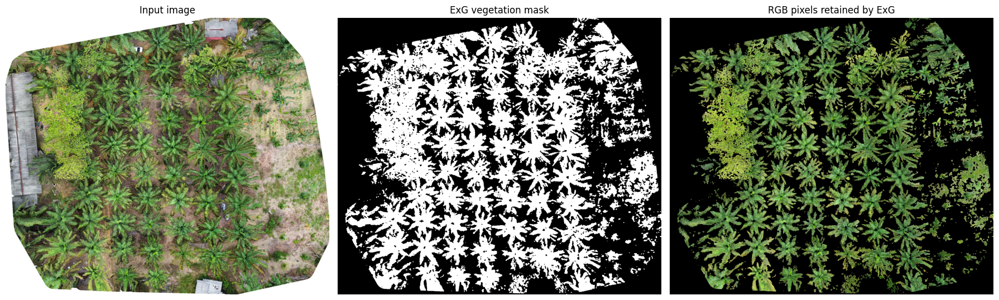

Image size: 1,950 × 1,664 px; vegetation pixels: 1,382,970 (42.6%)


In [72]:
image_path = Path(IMAGE_PATH)
model_path = Path(MODEL_PATH)
if not image_path.exists():
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
if not model_path.exists():
    raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")
print("1/6: Loading image and running ExG segmentation...")
original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise ValueError(f"Could not read image: {image_path}")
height, width = original_bgr.shape[:2]
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)
cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)

# Visual checkpoint: source image, binary vegetation mask, and segmented RGB result.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(original_rgb); axes[0].set_title("Input image"); axes[0].axis("off")
axes[1].imshow(exg_mask, cmap="gray", vmin=0, vmax=255); axes[1].set_title("ExG vegetation mask"); axes[1].axis("off")
axes[2].imshow(segmented_rgb); axes[2].set_title("RGB pixels retained by ExG"); axes[2].axis("off")
plt.tight_layout(); plt.show(); plt.close(fig)
print(f"Image size: {width:,} × {height:,} px; vegetation pixels: {int(np.count_nonzero(exg_mask)):,} ({np.mean(exg_mask > 0):.1%})")


## Step 2 — Detect and filter palm trees

2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 47 valid trees; filtered out 0 undersized and 0 oversized detections.


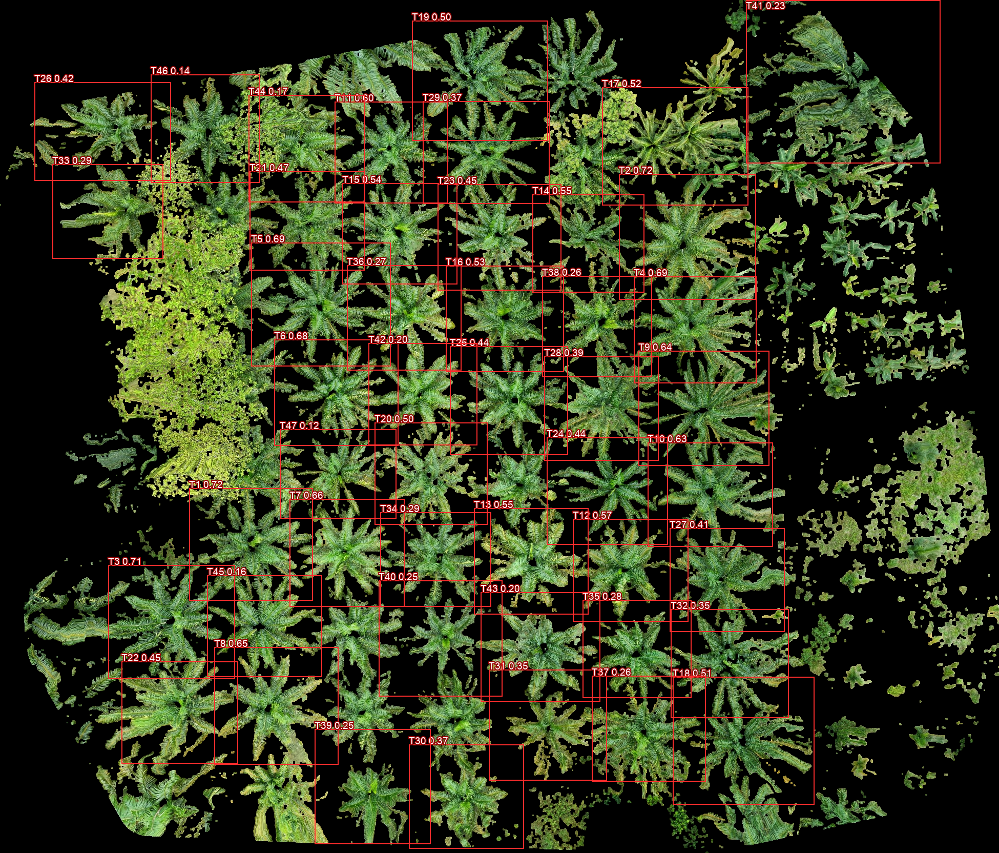

Measure,Value
Raw model detections after confidence/NMS,47
Kept trees,47
Filtered as undersized/partial,0
Filtered as oversized,0
Confidence threshold,0.1


In [73]:
print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
model = ct.models.MLModel(str(model_path))
normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
raw_trees = []
for box, score in zip(normalized_boxes, scores):
    bbox = normalized_box_to_pixels(box, width, height)
    bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
    if bw <= 0 or bh <= 0:
        continue
    raw_trees.append({
        "confidence": float(score),
        "bbox": bbox,
        "width": bw,
        "height": bh,
        "area": bw * bh,
        "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
        "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
    })
# Reference full-tree size from interior trees (not clipped by image borders)
interior_trees = [
    t for t in raw_trees
    if t["bbox"][0] > BORDER_MARGIN_PX
    and t["bbox"][1] > BORDER_MARGIN_PX
    and t["bbox"][2] < (width - BORDER_MARGIN_PX)
    and t["bbox"][3] < (height - BORDER_MARGIN_PX)
]
ref_pool = interior_trees if interior_trees else raw_trees
if ref_pool:
    median_w = float(np.median([t["width"] for t in ref_pool]))
    median_h = float(np.median([t["height"] for t in ref_pool]))
    median_area = float(np.median([t["area"] for t in ref_pool]))
else:
    median_w = median_h = median_area = 0.0
# Keep only trees that are at least 70% of typical width, height, and area
trees = []
skipped_partial = 0
skipped_oversized = 0
for t in raw_trees:
    w_ratio = t["width"] / median_w if median_w > 0 else 1.0
    h_ratio = t["height"] / median_h if median_h > 0 else 1.0
    area_ratio = t["area"] / median_area if median_area > 0 else 1.0
    if (
        w_ratio < MIN_TREE_COMPLETENESS
        or h_ratio < MIN_TREE_COMPLETENESS
        or area_ratio < MIN_TREE_COMPLETENESS
    ):
        skipped_partial += 1
        continue
    if (
        w_ratio > MAX_TREE_DIMENSION_MULTIPLIER
        or h_ratio > MAX_TREE_DIMENSION_MULTIPLIER
        or area_ratio > MAX_TREE_AREA_MULTIPLIER
    ):
        skipped_oversized += 1
        continue
    t["tree_id"] = len(trees) + 1
    trees.append(t)
print(
    f"Detected {len(trees)} valid trees; filtered out {skipped_partial} undersized and "
    f"{skipped_oversized} oversized detections."
)

# Visual checkpoint: show the detections used by downstream VARI and zoning steps.
detection_preview = Image.fromarray(segmented_rgb.copy())
draw_detection_preview = ImageDraw.Draw(detection_preview)
try:
    preview_font = ImageFont.truetype("Arial.ttf", max(12, min(22, width // 100)))
except OSError:
    preview_font = ImageFont.load_default()
for tree in trees:
    box = tree["bbox"]
    draw_detection_preview.rectangle(box, outline=(255, 45, 45), width=max(2, width // 1500))
    draw_detection_preview.text((box[0], max(0, box[1] - 18)), f"T{tree['tree_id']} {tree['confidence']:.2f}", fill="white", stroke_width=2, stroke_fill=(150, 0, 0), font=preview_font)
display(detection_preview)
show_preview_table("Detection filtering summary", ["Measure", "Value"], [
    ["Raw model detections after confidence/NMS", len(raw_trees)],
    ["Kept trees", len(trees)],
    ["Filtered as undersized/partial", skipped_partial],
    ["Filtered as oversized", skipped_oversized],
    ["Confidence threshold", CONF_THRESHOLD],
])


## Steps 3–4 — Calculate tree VARI, group zones, and calculate confidence

Step 4 shows the confidence formula, every zone’s intermediate factors, and the tree-count-weighted field confidence. The same shared formula is used later when the final zone recommendations are built.


In [74]:
print("3/6: Calculating VARI map and tree-level statistics...")
b, g, r = cv2.split(original_bgr)
b = b.astype(np.float32)
g = g.astype(np.float32)
r = r.astype(np.float32)
denominator = g + r - b
vari_map = np.full((height, width), np.nan, dtype=np.float32)
valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
np.divide(g - r, denominator, out=vari_map, where=valid)
for tree in trees:
    tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
    tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)
print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
zones = group_trees_into_zones(
    trees,
    grid_rows=ZONE_GRID_ROWS,
    grid_cols=ZONE_GRID_COLS,
    row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
    max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
    zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
    image_width=width,
    image_height=height,
)
pre_merge_zone_count = len(zones)
zones = merge_small_adjacent_zones(zones)
if len(zones) < pre_merge_zone_count:
    print(f"Merged {pre_merge_zone_count - len(zones)} undersized zone(s) into adjacent zones.")

# Step 4 confidence preview. The leaf-pixel count below uses the same union of tree boxes
# intersected with finite VARI pixels and the ExG mask as the final zone-statistics step.
all_tree_leaf_counts = [
    int(tree.get("vari", {}).get("vegetation_pixel_count") or 0)
    for zone in zones for tree in zone.get("trees", [])
    if int(tree.get("vari", {}).get("vegetation_pixel_count") or 0) > 0
]
step4_median_leaf_pixels_per_tree = float(np.median(all_tree_leaf_counts)) if all_tree_leaf_counts else 0.0
step4_flight_confidence = (DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None
                           else float(FLIGHT_CONFIDENCE))
step4_flight_source = ("DEFAULT_ZONE_CONFIDENCE stand-in" if FLIGHT_CONFIDENCE is None
                       else "configured FLIGHT_CONFIDENCE")
step4_confidence_rows = []
for zone in zones:
    zx1, zy1, zx2, zy2 = zone["bbox"]
    zone_tree_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)
    for tree in zone["trees"]:
        tx1, ty1, tx2, ty2 = tree["bbox"]
        lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
        lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
        if lx2 > lx1 and ly2 > ly1:
            zone_tree_union[ly1:ly2, lx1:lx2] = True
    zone_vari_crop = vari_map[zy1:zy2, zx1:zx2]
    zone_exg_crop = exg_mask[zy1:zy2, zx1:zx2] > 0
    leaf_pixel_count = int(np.count_nonzero(zone_tree_union & zone_exg_crop & np.isfinite(zone_vari_crop)))
    zone_id = zone["zone_id"]
    override = ZONE_CONFIDENCE_BY_ID.get(str(zone_id), ZONE_CONFIDENCE_BY_ID.get(zone_id))
    parts = calculate_zone_confidence_components(
        len(zone["trees"]), leaf_pixel_count, step4_median_leaf_pixels_per_tree,
        step4_flight_confidence, override,
    )
    zone["_step4_confidence_preview"] = parts
    step4_confidence_rows.append((zone, parts))

show_preview_table(
    "Step 4 — Zone confidence calculation inputs and results",
    ["Zone", "Trees", "Zone ExG/VARI pixels", "Median pixels/tree", "Tree factor", "Coverage ratio", "Leaf factor", "Zone factor", "Flight factor", "Raw → clamped", "Override", "Local confidence"],
    [[f"Z{zone['zone_id']}", len(zone["trees"]), parts["leaf_pixel_count"],
      f"{step4_median_leaf_pixels_per_tree:.2f}", f"{parts['tree_factor']:.4f}",
      f"{parts['leaf_pixel_ratio']:.4f}", f"{parts['leaf_pixel_factor']:.4f}",
      f"{parts['zone_factor']:.4f}", f"{step4_flight_confidence:.4f}",
      f"{parts['raw_confidence']:.4f} → {parts['calculated_confidence']:.4f}",
      "none" if parts["manual_override"] is None else f"{float(parts['manual_override']):.4f}",
      f"{parts['confidence']:.4f}"]
     for zone, parts in step4_confidence_rows],
)
print("Step 4 confidence formula:")
print(f"  Tree factor = min(1, sqrt(tree count ÷ {ZONE_CONFIDENCE_FULL_TREES:g} full-tree reference))")
print(f"  Leaf coverage ratio = zone ExG/VARI pixels ÷ (tree count × {step4_median_leaf_pixels_per_tree:.2f} median pixels/tree)")
print(f"  Leaf factor = min(1, leaf coverage ratio ÷ {ZONE_LEAF_PIXEL_FULL_RATIO:g} full-coverage reference)")
print("  Zone factor = tree factor × leaf factor")
print(f"  Flight factor = {step4_flight_confidence:.4f} ({step4_flight_source})")
print(f"  Calculated local confidence = clamp(flight factor × zone factor, {ZONE_CONFIDENCE_FLOOR:.2f}, 1.00)")
print("  A configured per-zone confidence override replaces the calculated local confidence.")
for zone, parts in step4_confidence_rows:
    n = len(zone["trees"])
    print(f"  Z{zone['zone_id']}: tree factor=min(1,sqrt({n}/{ZONE_CONFIDENCE_FULL_TREES:g}))={parts['tree_factor']:.6f}; "
          f"leaf ratio={parts['leaf_pixel_count']}/({n}×{step4_median_leaf_pixels_per_tree:.6f})={parts['leaf_pixel_ratio']:.6f}; "
          f"leaf factor=min(1,{parts['leaf_pixel_ratio']:.6f}/{ZONE_LEAF_PIXEL_FULL_RATIO:g})={parts['leaf_pixel_factor']:.6f}; "
          f"zone factor={parts['tree_factor']:.6f}×{parts['leaf_pixel_factor']:.6f}={parts['zone_factor']:.6f}; "
          f"raw confidence={step4_flight_confidence:.6f}×{parts['zone_factor']:.6f}={parts['raw_confidence']:.6f}; "
          f"clamped={parts['calculated_confidence']:.6f}; final local={parts['confidence']:.6f}")
step4_total_trees = sum(len(zone["trees"]) for zone in zones)
step4_field_confidence_raw = (
    sum(parts["confidence"] * len(zone["trees"]) for zone, parts in step4_confidence_rows) / step4_total_trees
    if step4_total_trees else 0.0
)
step4_field_confidence = min(1.0, max(ZONE_CONFIDENCE_FLOOR, step4_field_confidence_raw))
step4_weighted_terms = " + ".join(
    f"({parts['confidence']:.6f}×{len(zone['trees'])})" for zone, parts in step4_confidence_rows
)
print("  Overall field confidence = tree-count-weighted mean of local zone confidence:")
print(f"    ({step4_weighted_terms}) ÷ {step4_total_trees} trees = {step4_field_confidence_raw:.6f}")
print(f"    Clamp to [{ZONE_CONFIDENCE_FLOOR:.2f}, 1.00] = {step4_field_confidence:.6f}")

# Data checkpoint: tree VARI records and the spatial groups formed from detected trees.
show_preview_table("Tree-level VARI sample (first 12 trees)", ["Tree", "Zone", "Confidence", "Mean VARI", "Median VARI", "Vegetation pixels"], [
    [f"T{t['tree_id']}", next((f"Z{z['zone_id']}" for z in zones if t in z["trees"]), "—"),
     f"{t['confidence']:.3f}",
     f"{t['vari']['mean_vari']:.4f}" if t["vari"]["mean_vari"] is not None else "N/A",
     f"{t['vari']['median_vari']:.4f}" if t["vari"]["median_vari"] is not None else "N/A",
     t["vari"]["vegetation_pixel_count"]]
    for t in trees[:12]
])
show_preview_table("Zone grouping checkpoint", ["Zone", "Trees", "Approx. row", "Bounding box (px)"], [
    [f"Z{z['zone_id']}", len(z["trees"]), z.get("approx_row"), str(z["bbox"])] for z in zones
])


3/6: Calculating VARI map and tree-level statistics...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
Merged 1 undersized zone(s) into adjacent zones.


Zone,Trees,Zone ExG/VARI pixels,Median pixels/tree,Tree factor,Coverage ratio,Leaf factor,Zone factor,Flight factor,Raw → clamped,Override,Local confidence
Z1,7,160076,23504.00,0.8819,0.9729,1.0000,0.8819,0.6000,0.5292 → 0.5292,none,0.5292
Z2,9,172729,23504.00,1.0000,0.8165,1.0000,1.0000,0.6000,0.6000 → 0.6000,none,0.6000
Z3,8,213742,23504.00,0.9428,1.1367,1.0000,0.9428,0.6000,0.5657 → 0.5657,none,0.5657
Z4,6,132809,23504.00,0.8165,0.9417,1.0000,0.8165,0.6000,0.4899 → 0.4899,none,0.4899
Z5,9,161582,23504.00,1.0000,0.7639,1.0000,1.0000,0.6000,0.6000 → 0.6000,none,0.6000
Z6,8,154669,23504.00,0.9428,0.8226,1.0000,0.9428,0.6000,0.5657 → 0.5657,none,0.5657


Step 4 confidence formula:
  Tree factor = min(1, sqrt(tree count ÷ 9 full-tree reference))
  Leaf coverage ratio = zone ExG/VARI pixels ÷ (tree count × 23504.00 median pixels/tree)
  Leaf factor = min(1, leaf coverage ratio ÷ 0.7 full-coverage reference)
  Zone factor = tree factor × leaf factor
  Flight factor = 0.6000 (DEFAULT_ZONE_CONFIDENCE stand-in)
  Calculated local confidence = clamp(flight factor × zone factor, 0.10, 1.00)
  A configured per-zone confidence override replaces the calculated local confidence.
  Z1: tree factor=min(1,sqrt(7/9))=0.881917; leaf ratio=160076/(7×23504.000000)=0.972941; leaf factor=min(1,0.972941/0.7)=1.000000; zone factor=0.881917×1.000000=0.881917; raw confidence=0.600000×0.881917=0.529150; clamped=0.529150; final local=0.529150
  Z2: tree factor=min(1,sqrt(9/9))=1.000000; leaf ratio=172729/(9×23504.000000)=0.816547; leaf factor=min(1,0.816547/0.7)=1.000000; zone factor=1.000000×1.000000=1.000000; raw confidence=0.600000×1.000000=0.600000; clamped=

Tree,Zone,Confidence,Mean VARI,Median VARI,Vegetation pixels
T1,Z4,0.724,0.2037,0.1930,32036
T2,Z3,0.717,0.1876,0.1831,36101
T3,Z4,0.714,0.2553,0.2397,29954
T4,Z3,0.694,0.2337,0.2313,32284
T5,Z1,0.686,0.2247,0.2118,37049
T6,Z1,0.675,0.2064,0.1893,24430
T7,Z5,0.662,0.1772,0.1667,23090
T8,Z4,0.651,0.1527,0.1422,25811
T9,Z3,0.638,0.2372,0.2294,33261
T10,Z6,0.628,0.2448,0.2321,24271


Zone,Trees,Approx. row,Bounding box (px)
Z1,7,1,"[36, 114, 808, 900]"
Z2,9,1,"[622, 9, 1139, 918]"
Z3,8,1,"[1008, 0, 1866, 939]"
Z4,6,2,"[180, 806, 804, 1522]"
Z5,9,2,"[534, 793, 1215, 1664]"
Z6,8,2,"[1036, 822, 1620, 1600]"


## Step 5 — Calculate zone VARI and apply the fertilizer boost

In [75]:
print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
try:
    font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
except OSError:
    font = ImageFont.load_default()
tree_line_width = max(2, width // 1500)
MASK_OVERLAY_ALPHA = 0.60
# Image 3: CoreML object detections drawn on the ExG-segmented RGB image
coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
for tree in trees:
    tb = tree["bbox"]
    draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
    tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
    tx, ty = tb[0], max(0, tb[1] - 18)
    draw_coreml_exg.text(
        (tx, ty), tree_label,
        fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
    )
coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)
# Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
zone_tree_mask_rgb = np.zeros_like(original_rgb)
# Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
zone_tree_overlay_rgb = original_rgb.copy()
cmap_zones = plt.colormaps["tab20"]
zone_label_positions = []
zone_json = []
zone_exg_seed_masks = []
for zone in zones:
    zb = zone["bbox"]
    zx1, zy1, zx2, zy2 = zb
    tree_records = []
# Pick a unique RGB color for this zone
    rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
    zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
    zone_color = tuple(int(v) for v in zone_color_u8)
    zone_exg_seed_mask = np.zeros((height, width), dtype=np.uint8)
# Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
    tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)
    for tree in zone["trees"]:
        tx1, ty1, tx2, ty2 = tree["bbox"]
        tree_records.append({
            "tree_id": tree["tree_id"],
            "confidence": tree["confidence"],
            "bbox": tree["bbox_annotation"],
            "vari": tree["vari"],
        })
# Get ExG mask pixels inside this tree's detection area
        tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0
        zone_exg_seed_mask[ty1:ty2, tx1:tx2][tree_exg_mask] = 255
# 1) Color the tree's ExG mask pixels on the black canvas
        zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8
# 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
        orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
        orig_crop[tree_exg_mask] = (
            orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
            + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
        ).astype(np.uint8)
# Mark this tree's region inside the zone union mask
        lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
        lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
        if lx2 > lx1 and ly2 > ly1:
            tree_box_union[ly1:ly2, lx1:lx2] = True
    zone_exg_seed_masks.append(zone_exg_seed_mask)
# Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
    vari_crop = vari_map[zy1:zy2, zx1:zx2]
    mask_crop = (exg_mask[zy1:zy2, zx1:zx2] > 0) & tree_box_union
    valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if valid_vals.size == 0:
        zone_stats = {
            "vegetation_pixel_count": 0,
            "mean_vari": None, "median_vari": None,
            "std_vari": None, "mad_vari": None,
            "min_vari": None, "max_vari": None,
        }
    else:
        med = float(np.median(valid_vals))
        zone_stats = {
            "vegetation_pixel_count": int(valid_vals.size),
            "mean_vari": float(np.mean(valid_vals)),
            "median_vari": med,
            "std_vari": float(np.std(valid_vals)),
            "mad_vari": float(np.median(np.abs(valid_vals - med))),
            "min_vari": float(np.min(valid_vals)),
            "max_vari": float(np.max(valid_vals)),
        }
    zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
    zx, zy = zx1, max(0, zy1 - 28)
    zone_label_positions.append((zx, zy, zone_label, zone_color))
    zone_json.append({
        "zone_id": zone["zone_id"],
        "approx_row": zone["approx_row"],
        "tree_count": len(tree_records),
        "bbox": pixel_bbox_record(zb, width, height),
        "vari": zone_stats,
        "trees": tree_records,
    })
reference_mean = add_zone_boost_and_fertilizer(zone_json, image_size=(width, height))
zones_only_img = Image.fromarray(zone_tree_mask_rgb)
draw_zones_only = ImageDraw.Draw(zones_only_img)
combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
draw_combined = ImageDraw.Draw(combined_annotated_img)

# Data checkpoint: zone VARI, confidence, boost mode, and applied nutrient supplements.
show_preview_table("Zone statistics and boost preview", ["Zone", "Trees", "Mean VARI", "Median", "Min", "Max", "Field confidence", "Boost mode", "Mg kg/zone/year", "N kg/zone/year"], [
    [f"Z{z['zone_id']}", z["tree_count"],
     *[f"{z.get('vari', {}).get(k):.4f}" if z.get("vari", {}).get(k) is not None else "N/A" for k in ("mean_vari", "median_vari", "min_vari", "max_vari")],
     f"{z.get('recommendation', {}).get('overall_field_confidence', 0):.3f}",
     ("Blanket P25" if z.get("recommendation", {}).get("boost_mode") == "blanket_p25" else "Zone-specific"),
     f"{z.get('recommendation', {}).get('fertilizers', {}).get('kieserite_Mg_expensive', {}).get('annual_total_kg', 0):.4f}",
     f"{z.get('recommendation', {}).get('fertilizers', {}).get('urea_N_expensive', {}).get('annual_total_kg', 0):.4f}"]
    for z in zone_json
])


5/6: Coloring ExG tree masks by zone and calculating zone statistics...


Zone,Trees,Mean VARI,Median,Min,Max,Field confidence,Boost mode,Mg kg/zone/year,N kg/zone/year
Z1,7,0.2043,0.1944,-0.1829,1.0000,0.564,Zone-specific,0.1675,1.1599
Z2,9,0.2297,0.2176,-0.0969,1.6818,0.564,Zone-specific,0.0682,0.4718
Z3,8,0.2218,0.2105,-0.1145,1.4483,0.564,Zone-specific,0.1012,0.7009
Z4,6,0.2003,0.1911,-0.1023,1.4211,0.564,Zone-specific,0.1593,1.1032
Z5,9,0.1885,0.1761,-0.1053,1.7000,0.564,Zone-specific,0.3075,2.1290
Z6,8,0.2453,0.2313,-0.1268,1.2692,0.564,Zone-specific,0.0000,0.0000


## Step 6 — Create zone annotations, white separators, and zone centers

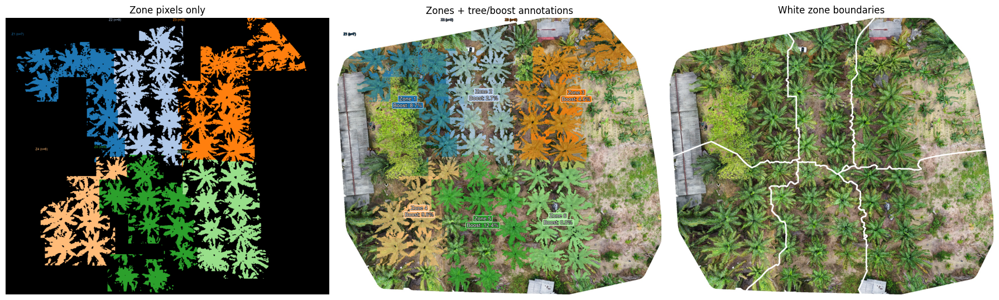

Zone,Center x (px),Center y (px),Normalized x,Normalized y
Z1,399.28,497.08,0.204759,0.298728
Z2,934.45,445.59,0.479206,0.26778
Z3,1460.15,466.2,0.748795,0.280168
Z4,360.62,1181.33,0.184932,0.709932
Z5,895.36,1310.28,0.459159,0.787431
Z6,1541.47,1232.04,0.790496,0.740411


In [76]:
# Draw only the Zone ID text labels (no bounding boxes)
for zx, zy, zone_label, zone_color in zone_label_positions:
    for canvas in (draw_zones_only, draw_combined):
        canvas.text(
            (zx, zy), zone_label,
            fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
        )
# Center the calculated boost percentage over each zone on the combined
# zones + tree annotations image. Boost is computed after VARI aggregation.
boost_font_size = max(16, min(36, width // 60))
try:
    boost_font = ImageFont.truetype("Arial.ttf", boost_font_size)
except OSError:
    boost_font = ImageFont.load_default()
for zone, zone_color in zip(zone_json, [
    tuple(int(round(c * 255)) for c in cmap_zones((z["zone_id"] - 1) % 20 / 20.0)[:3])
    for z in zones
]):
    rec = zone.get("recommendation", {})
    boost = rec.get("boost_fraction")
    if rec.get("boost_mode") == "blanket_p25":
        boost_text = f"Blanket P25: {boost * 100:.1f}%" if boost is not None else "Blanket P25: N/A"
    else:
        boost_text = f"Boost: {boost * 100:.1f}%" if boost is not None else "Boost: N/A"
    box = zone["bbox"]
    center = ((box["x1"] + box["x2"]) // 2, (box["y1"] + box["y2"]) // 2)
    pad = max(5, boost_font_size // 5)
    zone_font = boost_font
    zone_center = (center[0], center[1] - int(boost_font_size * 0.65))
    boost_center = (center[0], center[1] + int(boost_font_size * 0.65))
    for label, label_center, label_font in (
        (f"Zone {zone['zone_id']}", zone_center, zone_font),
        (boost_text, boost_center, boost_font),
    ):
        text_box = draw_combined.textbbox(label_center, label, font=label_font, anchor="mm", stroke_width=2)
        draw_combined.rounded_rectangle(
            (text_box[0] - pad, text_box[1] - pad, text_box[2] + pad, text_box[3] + pad),
            radius=max(4, pad), fill=zone_color, outline=(255, 255, 255), width=2,
        )
        draw_combined.text(
            label_center, label, fill=(255, 255, 255), font=label_font, anchor="mm",
            stroke_width=2, stroke_fill=(0, 0, 0),
        )
white_separator_img = Image.fromarray(original_rgb.copy())
zone_centers = []
for zone, source_zone in zip(zone_json, zones):
    centers = [tree["center"] for tree in source_zone["trees"]]
    if centers:
        zone_centers.append((float(np.mean([p[0] for p in centers])),
                             float(np.mean([p[1] for p in centers]))))
    else:
        box = zone["bbox"]
        zone_centers.append(((box["x1"] + box["x2"]) / 2,
                             (box["y1"] + box["y2"]) / 2))
# Assign each image pixel to the nearest zone's actual ExG tree-mask seed.
# This follows the same colored vegetation pixels as the original zoning
# output, while producing one shared boundary between neighboring zones.
yy, xx = np.ogrid[:height, :width]
nearest_zone = np.zeros((height, width), dtype=np.int16)
nearest_distance = np.full((height, width), np.inf, dtype=np.float32)
for zone_index, (zone_seed_mask, (center_x, center_y)) in enumerate(zip(zone_exg_seed_masks, zone_centers)):
    if np.any(zone_seed_mask):
        non_seed_pixels = np.where(zone_seed_mask > 0, 0, 255).astype(np.uint8)
        distance = cv2.distanceTransform(non_seed_pixels, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    else:
        distance = np.sqrt((xx - center_x) ** 2 + (yy - center_y) ** 2).astype(np.float32)
    closer = distance < nearest_distance
    nearest_zone[closer] = zone_index
    nearest_distance[closer] = distance[closer]
separator_mask = np.zeros((height, width), dtype=bool)
separator_mask[:, 1:] |= nearest_zone[:, 1:] != nearest_zone[:, :-1]
separator_mask[1:, :] |= nearest_zone[1:, :] != nearest_zone[:-1, :]
separator_width = max(1, int(WHITE_ZONE_BOUNDARY_WIDTH_PX))
if separator_width % 2 == 0:
    separator_width += 1
separator_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (separator_width, separator_width)
)
separator_mask = cv2.dilate(separator_mask.astype(np.uint8), separator_kernel) > 0
white_separator_rgb = original_rgb.copy()
white_separator_rgb[separator_mask] = (255, 255, 255)
white_separator_img = Image.fromarray(white_separator_rgb)
zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)
white_separator_img.save(OUTPUT_WHITE_ZONE_ANNOTATED, quality=95)
# Calculate each zone's center point based on the white separator zoning segmentation image.
grid_y, grid_x = np.indices((height, width))
is_white_bg = np.all(original_rgb >= 240, axis=-1)
for zone_index, zone in enumerate(zone_json):
    zone_partition_mask = (nearest_zone == zone_index) & (~separator_mask)
    zone_visible_mask = zone_partition_mask & (~is_white_bg)
    active_mask = (
        zone_visible_mask
        if np.any(zone_visible_mask)
        else (zone_partition_mask if np.any(zone_partition_mask) else (nearest_zone == zone_index))
    )
    cx = float(np.mean(grid_x[active_mask]))
    cy = float(np.mean(grid_y[active_mask]))
    part_mask = (nearest_zone == zone_index)
    cx_part = float(np.mean(grid_x[part_mask]))
    cy_part = float(np.mean(grid_y[part_mask]))
    zone["center_point"] = {
        "x": round(cx, 2),
        "y": round(cy, 2),
        "normalized_x": round(cx / width, 6),
        "normalized_y": round(cy / height, 6),
    }
    zone["center"] = {
        "x": round(cx, 2),
        "y": round(cy, 2),
    }
    zone["partition_center_point"] = {
        "x": round(cx_part, 2),
        "y": round(cy_part, 2),
        "normalized_x": round(cx_part / width, 6),
        "normalized_y": round(cy_part / height, 6),
    }

# Visual checkpoint: compare the clean white-boundary image with the zone overlay and annotations.
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
axes[0].imshow(zones_only_img); axes[0].set_title("Zone pixels only"); axes[0].axis("off")
axes[1].imshow(combined_annotated_img); axes[1].set_title("Zones + tree/boost annotations"); axes[1].axis("off")
axes[2].imshow(white_separator_img); axes[2].set_title("White zone boundaries"); axes[2].axis("off")
plt.tight_layout(); plt.show(); plt.close(fig)
show_preview_table("Zone center points", ["Zone", "Center x (px)", "Center y (px)", "Normalized x", "Normalized y"], [
    [f"Z{z['zone_id']}", z["center_point"]["x"], z["center_point"]["y"], z["center_point"]["normalized_x"], z["center_point"]["normalized_y"]]
    for z in zone_json
])


## Step 7 — Save per-zone image crops

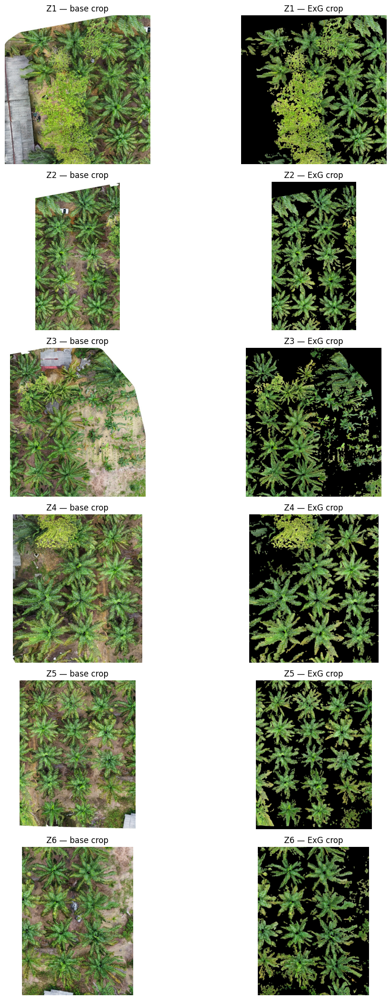

In [77]:
zone_base_crops_dir = Path(OUTPUT_ZONE_BASE_CROPS_DIR)
zone_exg_crops_dir = Path(OUTPUT_ZONE_EXG_CROPS_DIR)
zone_base_crops_dir.mkdir(parents=True, exist_ok=True)
zone_exg_crops_dir.mkdir(parents=True, exist_ok=True)
for zone in zone_json:
    box = zone["bbox"]
    crop_bounds = (
        max(0, int(box["x1"])), max(0, int(box["y1"])),
        min(width, int(box["x2"])), min(height, int(box["y2"])),
    )
    if crop_bounds[2] <= crop_bounds[0] or crop_bounds[3] <= crop_bounds[1]:
        zone["base_image_crop"] = None
        zone["exg_image_crop"] = None
        continue
    zone_name = f"zone_{int(zone['zone_id']):02d}.jpg"
    base_crop_path = zone_base_crops_dir / zone_name
    exg_crop_path = zone_exg_crops_dir / zone_name
    Image.fromarray(original_rgb).crop(crop_bounds).save(base_crop_path, quality=95)
    Image.fromarray(segmented_rgb).crop(crop_bounds).save(exg_crop_path, quality=95)
    zone["base_image_crop"] = str(base_crop_path.resolve())
    zone["exg_image_crop"] = str(exg_crop_path.resolve())

# Visual checkpoint: show base-image and ExG crops side by side for each zone.
if zone_json:
    fig, axes = plt.subplots(len(zone_json), 2, figsize=(12, max(4, 3.5 * len(zone_json))), squeeze=False)
    for row, zone in enumerate(zone_json):
        base_path = zone.get("base_image_crop")
        exg_path = zone.get("exg_image_crop")
        if base_path and Path(base_path).exists():
            axes[row, 0].imshow(plt.imread(base_path))
        axes[row, 0].set_title(f"Z{zone['zone_id']} — base crop"); axes[row, 0].axis("off")
        if exg_path and Path(exg_path).exists():
            axes[row, 1].imshow(plt.imread(exg_path))
        axes[row, 1].set_title(f"Z{zone['zone_id']} — ExG crop"); axes[row, 1].axis("off")
    plt.tight_layout(); plt.show(); plt.close(fig)


## Step 8 — Write tables, CSV files, plots, and JSON output
The next cell prints **Separate VARI Supplement Product-Mass Conversion (annual)**. Dolomite and Kieserite each default to a base of 1.0 kg/palm/year; a dose entered for that product replaces its default using dose per tree × applications per year. The **Base product** and **Base+supplement** columns show that base separately from any zone VARI boost. The two Mg products are alternatives; choose one rather than adding both rows together. The output prints each base-rate source. The same base and combined amounts are saved in `oil_palm_zone_fertilizer_product_mass.csv` and, after the final app-data cell runs, in each zone's `ui_data.zone_recommendations[].product_supplement_options`. Run the notebook from the beginning to refresh these outputs.



--- Zone VARI-Derived Nutrient Supplement Summary (annual) ---
Notebook confidence thresholds are proposals/guesses pending calibration against field observations.
Min VARI review flags every zone tied for the lowest valid zone minimum; it is a screening flag for follow-up, not a diagnosis.
Zone | Trees | Mean VARI | Min VARI | Min VARI review        | Zone factor | Zone confidence | Overall field confidence (applied) | Qualifies for P25/P95? | Raw zone boost | Boost mode / basis   | Additional Mg boost only                 | Additional N boost only                 
-----+-------+-----------+----------+------------------------+-------------+-----------------+------------------------------------+------------------------+----------------+----------------------+------------------------------------------+-----------------------------------------
Z1   | 7     | 0.204     | -0.183   | CHECK: lowest zone min | 0.8819      | 0.5292          | 0.5637                             | yes          

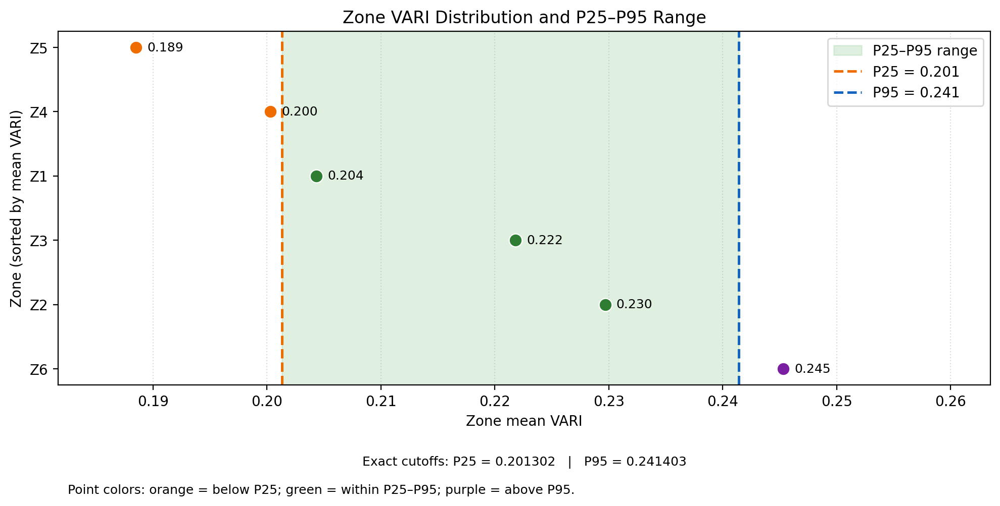

Output,Path
Zone summary CSV,/Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zone_vari_summary.csv
Fertilizer product-mass CSV,/Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zone_fertilizer_product_mass.csv
VARI distribution plot,/Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_vari_distribution.png
JSON result,/Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zones_vari.json


In [78]:
# Save CSV and print summary table
save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
print_zone_vari_table(zone_json)
product_mass_rows = build_and_print_product_mass_table(zone_json)
save_product_mass_csv(product_mass_rows, OUTPUT_PRODUCT_MASS_CSV)
save_vari_distribution_plot(zone_json, OUTPUT_VARI_DISTRIBUTION)
# Save JSON
result = {
    "metadata": {
        "source_image": str(image_path),
        "image_width_px": width,
        "image_height_px": height,
        "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
        "vari_formula": "(G - R) / (G + R - B)",
        "vari_distribution_plot": str(Path(OUTPUT_VARI_DISTRIBUTION).resolve()),
        "white_separator_zone_annotation_image": str(Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()),
        "zone_boost_formula": "Bi=max(0, 1-V_input/Vref)*zone_confidence; Vref/P25 use valid reference-zone means (zone factor >= configured threshold), falling back to all valid zones if none qualify; if P95-P25 gap <= configured cutoff, V_input=P25 for every zone, otherwise V_input=each zone mean",
        "zone_specific_boost_formula": "B_zone=max(0, 1-zone_mean_vari/Vref)*zone_confidence; shown for comparison even when P25 blanket mode is applied",
        "p25_zone_mean_vari": zone_json[0]["recommendation"].get("p25_zone_mean_vari") if zone_json else None,
        "p95_p25_vari_gap": zone_json[0]["recommendation"].get("p95_p25_vari_gap") if zone_json else None,
        "minimum_p95_p25_gap_for_blanket_boost": MIN_P95_P25_VARI_GAP_FOR_BLANKET_BOOST,
        "zone_boost_mode": zone_json[0]["recommendation"].get("boost_mode") if zone_json else "zone_specific",
        "zone_mean_vari_percentile_rank_definition": "100 × number of valid zone means less than or equal to this zone mean ÷ number of valid zones; empirical rank within this image only",
        "fertilizer_boost_formula": "Additional nutrient supplement: Mg_i=Bi*Mg_max; N_i=Bi*N_max; annual zone supplement kg=annual supplement kg/ha*zone area ha",
        "reference_zone_mean_vari": reference_mean,
        "lowest_zone_min_vari_value": (
            zone_json[0].get("vari", {}).get("lowest_zone_min_vari_value")
            if zone_json else None
        ),
        "lowest_zone_min_vari_flag_definition": (
            "Each zone tied for the lowest finite min_vari is flagged for review; this is an image-screening cue, not a diagnosis."
        ),
        "zone_confidence_rule": (
            "zone_factor=min(1,sqrt(tree_count/full_tree_count))*min(1,leaf_pixel_ratio/full_leaf_ratio); "
            "zone_local_confidence=clamp(flight_confidence*zone_factor,floor,1); "
            "optional ZONE_CONFIDENCE_BY_ID values override zone_local_confidence; "
            "overall_field_confidence=clamp(tree_count_weighted_mean(zone_local_confidence),floor,1); "
            "all zone boosts use the single overall_field_confidence"
        ),
        "overall_field_confidence": (
            zone_json[0]["recommendation"].get("overall_field_confidence") if zone_json else None
        ),
        "overall_field_confidence_raw": (
            zone_json[0]["confidence"].get("overall_field_confidence_raw") if zone_json else None
        ),
        "overall_field_confidence_aggregation": "sum(zone_local_confidence × tree_count) ÷ sum(tree_count), clamped to [0.10, 1.00]",
        "zone_confidence_parameters": {
            "full_tree_count": ZONE_CONFIDENCE_FULL_TREES,
            "full_leaf_pixel_ratio": ZONE_LEAF_PIXEL_FULL_RATIO,
            "reference_min_zone_factor": ZONE_REFERENCE_MIN_FACTOR,
            "confidence_floor": ZONE_CONFIDENCE_FLOOR,
            "field_confidence_weighting": "tree_count_weighted_mean",
            "suggested_min_reference_zones": MIN_REFERENCE_ZONES_SUGGESTED,
        },
        "flight_confidence": FLIGHT_CONFIDENCE,
        "flight_confidence_used": DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None else FLIGHT_CONFIDENCE,
        "flight_confidence_stand_in": DEFAULT_ZONE_CONFIDENCE if FLIGHT_CONFIDENCE is None else None,
        "reference_zone_ids": zone_json[0]["recommendation"].get("reference_zone_ids", []) if zone_json else [],
        "reference_fallback_all_zones": zone_json[0]["recommendation"].get("reference_fallback_all_zones") if zone_json else False,
        "zone_confidence_run_flags": zone_json[0]["recommendation"].get("zone_confidence_run_flags", []) if zone_json else [],
        "max_nutrient_targets_kg_ha_per_year": MAX_NUTRIENT_KG_HA_PER_YEAR,
        "fertilizer_nutrient_by_product": FERTILIZER_NUTRIENT_BY_PRODUCT,
        "fertilizer_product_nutrient_fractions": FERTILIZER_PRODUCT_NUTRIENT_FRACTIONS,
        "base_product_rates_kg_per_palm_per_year": FERTILIZER_BASE_PRODUCT_KG_PER_PALM_PER_YEAR,
        "fertilizer_output_scope": "VARI-scaled additional elemental nutrient supplement and its product-mass equivalent; full maintenance fertilizer schedule is not included unless a separate approved product base rate is configured",
        "fertilizer_prices_per_kg": FERTILIZER_PRICE_PER_KG,
        "configured_total_farm_area_ha": TOTAL_FARM_AREA_HA,
        "effective_total_zone_area_ha": sum(
            zone.get("recommendation", {}).get("zone_area_ha") or 0.0 for zone in zone_json
        ),
        "max_nutrient_totals_for_effective_farm_area_kg_per_year": {
            nutrient: float(rate) * sum(
                zone.get("recommendation", {}).get("zone_area_ha") or 0.0
                for zone in zone_json
            )
            for nutrient, rate in MAX_NUTRIENT_KG_HA_PER_YEAR.items()
            if rate is not None
        },
        "ground_area_source": (
            "user-supplied per-zone area mapping" if load_zone_areas()
            else "configured uniform area per zone" if UNIFORM_ZONE_AREA_HA is not None
            else "configured total farm area split by detected tree counts" if TOTAL_FARM_AREA_HA is not None
            else "approximate detected tree count × configured spacing²" if USE_SPACING_BASED_ZONE_AREA_DEFAULT
            else "not supplied"
        ),
        "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
        "model_path": str(model_path),
        "confidence_threshold": CONF_THRESHOLD,
        "maximum_tree_dimension_multiplier": MAX_TREE_DIMENSION_MULTIPLIER,
        "maximum_tree_area_multiplier": MAX_TREE_AREA_MULTIPLIER,
        "nms_iou_threshold": IOU_THRESHOLD,
        "trees_per_zone_max": TREES_PER_ZONE,
        "minimum_trees_to_keep_zone": MIN_TREES_TO_KEEP_ZONE,
        "zone_grouping": "Approximate image-row clustering; columns use fixed spatial bins based on median within-row tree spacing so missing detections do not shift subsequent bins; zone bbox encloses detected member boxes only",
        "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
        "detected_tree_count": len(trees),
        "zone_count": len(zone_json),
        "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary; center_point and center provide (x, y) coordinates for each zone based on the white-separator zoning image. normalized_xyxy and normalized_x/y values are divided by original image width/height.",
        "limitations": [
            "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
            "Zone confidence is a heuristic from tree count and ExG leaf-pixel coverage; notebook parameters marked GUESS require calibration against field observations.",
            "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
            "Zone VARI summarizes ExG-selected pixels in the union of member tree detection boxes; pixels in overlapping boxes are counted once.",
            "The optional P25 blanket-boost mode is a configurable spatial rule, not an agronomic diagnosis; validate its VARI gap cutoff for the imagery and management plan.",
            "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
            "Fertilizer rates and prices are illustrative/configurable and are not agronomic recommendations.",
            "Reported fertilizer boosts and totals are elemental Mg or N quantities; they are not converted to product mass.",
            "Ground zone areas are not derived from image pixels. Unless per-zone or uniform areas are supplied, the configured total farm area is allocated among zones in proportion to detected tree counts; missed detections can therefore affect area allocation. This is not a geospatial area measurement.",
        ],
    },
    "zones": zone_json,
    "fertilizer_product_mass_conversions": product_mass_rows,
}
with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)

# Output checkpoint: preview the distribution graphic and list the principal files written.
display(Image.open(OUTPUT_VARI_DISTRIBUTION))
show_preview_table("Files created in this step", ["Output", "Path"], [
    ["Zone summary CSV", str(Path(OUTPUT_ZONE_CSV).resolve())],
    ["Fertilizer product-mass CSV", str(Path(OUTPUT_PRODUCT_MASS_CSV).resolve())],
    ["VARI distribution plot", str(Path(OUTPUT_VARI_DISTRIBUTION).resolve())],
    ["JSON result", str(Path(OUTPUT_JSON).resolve())],
])


## Step 9 — Build and display the pipeline preview


6/6: Outputs written:
  1. ExG mask:                 /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_exg_mask.png
  2. ExG-segmented RGB:        /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_exg_segmented.jpg
  3. Detections on ExG image:  /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_coreml_detections.jpg
  4. Zones only (on original): /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zones_only.jpg
  5. Zones + trees (original): /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zones_annotated.jpg
  6. White-separator zoning:   /Us

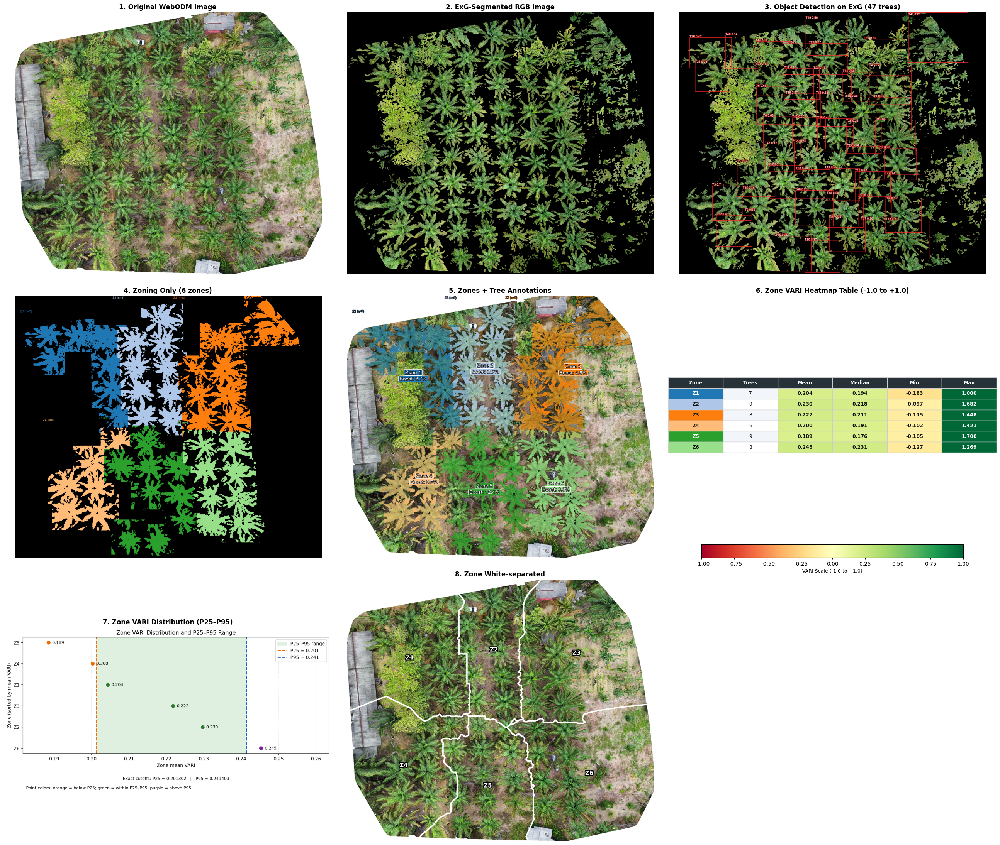

In [79]:
# Build and save the 3x3 visualization figure (5 images, VARI table, and distribution graphic)
fig, axes = plt.subplots(3, 3, figsize=(26, 22))
axes[0][0].imshow(original_rgb)
axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
axes[0][0].axis("off")
axes[0][1].imshow(segmented_rgb)
axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
axes[0][1].axis("off")
axes[0][2].imshow(coreml_on_exg_img)
axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
axes[0][2].axis("off")
axes[1][0].imshow(zones_only_img)
axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
axes[1][0].axis("off")
axes[1][1].imshow(combined_annotated_img)
axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
axes[1][1].axis("off")
# 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
ax_table = axes[1][2]
ax_table.axis("off")
ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")
if zone_json:
    cmap_vari = plt.colormaps["RdYlGn"]
    norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
    col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
    heatmap_cols = {2, 3, 4, 5}
    cell_text, cell_colors, text_colors = [], [], []
    for r_idx, z in enumerate(zone_json):
        st = z.get("vari", {})
        vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
        row_str = [
            f"Z{z['zone_id']}",
            str(z["tree_count"]),
            *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
        ]
        raw_row = [None, None, *vals]
        base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
        r_bg, r_fg = [], []
        for c_idx, v in enumerate(raw_row):
            if c_idx == 0:
                z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                r_bg.append(z_rgba)
                lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                r_fg.append("#111111" if lum > 0.52 else "#ffffff")
            elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                r_bg.append(rgba)
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                r_fg.append("#111111" if lum > 0.52 else "#ffffff")
            else:
                r_bg.append(base_bg)
                r_fg.append("#111111")
        cell_text.append(row_str)
        cell_colors.append(r_bg)
        text_colors.append(r_fg)
    tbl = ax_table.table(
        cellText=cell_text,
        colLabels=col_labels,
        cellColours=cell_colors,
        cellLoc="center",
        loc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1.0, 1.35)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#263238")
            cell.get_text().set_color("white")
            cell.get_text().set_weight("bold")
        else:
            cell.get_text().set_color(text_colors[r - 1][c])
            if c in heatmap_cols or c == 0:
                cell.get_text().set_weight("bold")
    sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
    cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
    cbar.set_ticks(np.linspace(-1.0, 1.0, 9))
axes[2][0].imshow(plt.imread(OUTPUT_VARI_DISTRIBUTION))
axes[2][0].set_title("7. Zone VARI Distribution (P25–P95)", fontsize=12, fontweight="bold")
axes[2][0].axis("off")
white_zone_ax = axes[2][1]
white_zone_ax.imshow(plt.imread(OUTPUT_WHITE_ZONE_ANNOTATED))
white_zone_ax.set_title("8. Zone White-separated", fontsize=12, fontweight="bold")
# Keep the exported white-separator image clean; add zone IDs only to this
# interactive pipeline preview.
for zone in zone_json:
    center = zone.get("center_point", {})
    if center.get("x") is None or center.get("y") is None:
        continue
    white_zone_ax.text(
        center["x"], center["y"], f"Z{zone['zone_id']}",
        color="white", fontsize=11, fontweight="bold",
        ha="center", va="center",
        path_effects=[path_effects.withStroke(linewidth=3, foreground="black")],
    )
white_zone_ax.axis("off")
axes[2][2].axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")
print("\n6/6: Outputs written:")
print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
print(f"  6. White-separator zoning:   {Path(OUTPUT_WHITE_ZONE_ANNOTATED).resolve()}")
print(f"  7. Base image zone crops:    {zone_base_crops_dir.resolve()} ({len(zone_json)} images)")
print(f"  8. ExG image zone crops:     {zone_exg_crops_dir.resolve()} ({len(zone_json)} images)")
print(f"  9. 7-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
print(f" 10. JSON output:              {Path(OUTPUT_JSON).resolve()}")
print(f" 11. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")
print(f" 12. Product mass CSV:         {Path(OUTPUT_PRODUCT_MASS_CSV).resolve()}")
print(f" 13. VARI distribution plot:   {Path(OUTPUT_VARI_DISTRIBUTION).resolve()}")
print(" 14. Zone Center Points (x, y) from white separator zoning:")
for z in zone_json:
    cp = z["center_point"]
    print(f"      Zone {z['zone_id']}: x = {cp['x']}, y = {cp['y']} (normalized: x = {cp['normalized_x']:.4f}, y = {cp['normalized_y']:.4f})")
if SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)


# Part 2 — Annual NPK/NPKMg comparison

This section adds the standalone `compare_npk_recommendation.py` workflow. It compares the configured annual blend use per hectare with the reference baseline, converts oxide-label values to elemental nutrients, and estimates separate N, P, K, and Mg supplements when needed. It runs independently of the image-zoning steps above.

Edit the input values in the configuration cell, then run the remaining cells in this section from top to bottom. The final report is shown in a horizontally scrollable, aligned output block.

## A. Configure the user fertilizer and reference values

Set the blend label, annual bags per hectare, bag size, comparison tolerance, baseline, and standalone product label guarantees here.

Standalone P/K options use **SP-36 (36% P₂O₅, 50 kg bag)** and **KCl/MOP (60% K₂O, 50 kg bag)**. Petrokimia Gresik documents the SP-36 label and 50 kg pack ([product specification](https://petrokimia-gresik.com/product/pupuk-sp-36)); PT PPI documents KCl/MOP at 60% K₂O ([product information](https://www.ptppi.co.id/product/detail/50)). Product labels are oxide-based, so the calculation converts the elemental P or K gap to product mass using the same oxide-to-element factors defined above. The bag sizes and label fractions are configurable in the code. KCl contains chloride, so verify it is suitable for the field and use the actual bag guarantee.


In [80]:
# Imports for this standalone comparison section (also works if this section is run by itself).
import math
import html as _npk_html
from contextlib import redirect_stdout as _npk_redirect_stdout
from io import StringIO as _NPKStringIO
from IPython.display import display as _npk_display, HTML as _NPKHTML

# Default values are used only when the submission has no NPK history item.
USER_FERTILIZER_ANALYSIS = "12-12-12"  # Fallback label: N-P2O5-K2O[-MgO], in percent.
USER_FERTILIZER_PRODUCT_NAME = None  # Optional brand/name for display in the app.
PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP = {}  # Optional prices, e.g. {"Urea": 200000}; keys must match product names.
USER_BAGS_PER_HA_PER_YEAR = 6.0  # Fallback annual NPK bags per hectare.
BAG_SIZE_KG = 50.0  # Fallback product mass per bag.

# Prefill the existing NPK comparison from the NPK record entered in the UI JSON.
# The form's P/K/Mg composition is interpreted as the standard fertilizer-label basis:
# N-P2O5-K2O-MgO. `bags` is treated as the annual bag count for this comparison.
_ui_fertilizer_entries = (UI_SUBMISSION_DATA.get("fertilizerHistory") or {}).get("fertilizers", [])
_ui_npk_entry = next((item for item in _ui_fertilizer_entries
                      if str(item.get("name", "")).strip().upper() == "NPK"), None)
_ui_farm_area_ha = float(UI_FARM_INPUT.get("areaHa") or 1.0)
if _ui_npk_entry is not None:
    _ui_comp = _ui_npk_entry.get("composition") or {}
    if all(key in _ui_comp for key in ("N", "P", "K", "Mg")):
        USER_FERTILIZER_ANALYSIS = "-".join(str(_ui_comp[key]) for key in ("N", "P", "K", "Mg"))
    USER_FERTILIZER_PRODUCT_NAME = _ui_npk_entry.get("name", "NPK")
    BAG_SIZE_KG = float(_ui_npk_entry.get("bagKg", BAG_SIZE_KG))
    USER_BAGS_PER_HA_PER_YEAR = float(_ui_npk_entry.get("bags", 0)) / _ui_farm_area_ha
OUTPUT_DECIMALS = 6  # Consistent decimal places for all displayed mass and rate values.
NUTRIENT_MATCH_TOLERANCE_PERCENT = 5.0  # Differences within ±5% of baseline are labeled close to target.
NPK_GAP_ROUTE_THRESHOLD_PERCENT = 30.0  # Route cutoff only: larger N/P/K gaps suggest reviewing blend quantity; tune for your policy.
ALTERNATIVE_NPK_PRODUCTS = {
    "Reference-style 12-6-22-3": "12-6-22-3",  # Optional candidate blends, in N-P2O5-K2O-MgO order.
}

# Current project baseline. Values are elemental nutrient rates in kg/ha/year.
BASELINE_ELEMENTAL_KG_HA_YEAR = {
    "N": 90.00,
    "P": 10.00,
    "K": 111.00,
    "Mg": 13.00,
}

# Standalone Mg products, using the same label-basis assumptions as
# oil_palm_zones_vari_fertilizer.py. Enter the guaranteed MgO fraction from
# the product label; the calculation converts MgO to elemental Mg in two steps.
STANDALONE_MG_PRODUCTS = {
    "Kieserite": {"mgo_fraction": 0.255, "bag_size_kg": 50.0},
    "Dolomite": {"mgo_fraction": 0.22, "bag_size_kg": 50.0},
}

# Standalone phosphorus products. SP-36 guarantees P2O5, not elemental P.
STANDALONE_P_PRODUCTS = {
    "SP-36": {"oxide_fraction": 0.36, "bag_size_kg": 50.0},
}

# Standalone potassium products. KCl/MOP guarantees K2O, not elemental K.
# Confirm chloride suitability and actual guaranteed analysis for the field/product.
STANDALONE_K_PRODUCTS = {
    "KCl / MOP": {"oxide_fraction": 0.60, "bag_size_kg": 50.0},
}

# Standalone nitrogen options, using the guaranteed elemental N fraction on the bag.
STANDALONE_N_PRODUCTS = {
    "ZA": {"n_fraction": 0.21, "bag_size_kg": 50.0},
    "Urea": {"n_fraction": 0.46, "bag_size_kg": 50.0},
}

# Atomic masses, used to convert fertilizer oxide label amounts to elemental masses.
ATOMIC_MASS_G_MOL = {"P": 30.973761998, "K": 39.0983, "Mg": 24.305, "O": 15.999}
OXIDE_TO_ELEMENT = {
    "P2O5": {
        "element": "P",
        "element_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["P"],
        "oxide_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["P"] + 5 * ATOMIC_MASS_G_MOL["O"],
    },
    "K2O": {
        "element": "K",
        "element_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["K"],
        "oxide_mass_g_mol": 2 * ATOMIC_MASS_G_MOL["K"] + ATOMIC_MASS_G_MOL["O"],
    },
    "MgO": {
        "element": "Mg",
        "element_mass_g_mol": ATOMIC_MASS_G_MOL["Mg"],
        "oxide_mass_g_mol": ATOMIC_MASS_G_MOL["Mg"] + ATOMIC_MASS_G_MOL["O"],
    },
}
for oxide_data in OXIDE_TO_ELEMENT.values():
    oxide_data["factor"] = oxide_data["element_mass_g_mol"] / oxide_data["oxide_mass_g_mol"]


## B. Parse labels and convert to elemental nutrients

These helpers interpret the bag label and calculate elemental N, P, K, and Mg supplied per hectare per year.

In [81]:
def parse_analysis(label):
    """Read N-P2O5-K2O[-MgO] percentages from a string such as '12-6-22-3'."""
    try:
        values = [float(value.strip()) for value in label.replace(",", "-").split("-")]
    except (AttributeError, ValueError) as exc:
        raise ValueError("Set USER_FERTILIZER_ANALYSIS as e.g. '15-15-15' or '12-6-22-3'.") from exc
    if len(values) == 3:
        values.append(0.0)
    if len(values) != 4 or any(not math.isfinite(value) or not 0 <= value <= 100 for value in values):
        raise ValueError("Enter three or four label percentages, each from 0 to 100.")
    return dict(zip(("N", "P2O5", "K2O", "MgO"), values))


def npk_fmt(value):
    """Format all displayed masses/rates to the configured common precision."""
    return f"{value:.{OUTPUT_DECIMALS}f}"


def build_annual_nutrients(label_percent, bags_per_ha_year, bag_size_kg=None):
    """Return elemental supply per hectare/year, optionally using an explicit bag size."""
    effective_bag_size_kg = BAG_SIZE_KG if bag_size_kg is None else float(bag_size_kg)
    if not math.isfinite(effective_bag_size_kg) or effective_bag_size_kg <= 0:
        raise ValueError("bag_size_kg must be greater than zero.")
    product_kg_ha_year = bags_per_ha_year * effective_bag_size_kg
    oxide_or_element_kg_ha_year = {
        nutrient: product_kg_ha_year * percent / 100.0
        for nutrient, percent in label_percent.items()
    }
    return {
        "N": oxide_or_element_kg_ha_year["N"],
        "P": oxide_or_element_kg_ha_year["P2O5"] * OXIDE_TO_ELEMENT["P2O5"]["factor"],
        "K": oxide_or_element_kg_ha_year["K2O"] * OXIDE_TO_ELEMENT["K2O"]["factor"],
        "Mg": oxide_or_element_kg_ha_year["MgO"] * OXIDE_TO_ELEMENT["MgO"]["factor"],
    }, oxide_or_element_kg_ha_year, product_kg_ha_year



## C. Calculate standalone N, P, K, and Mg options

For a positive Mg gap, this prints kieserite and dolomite as alternatives. Label MgO is converted to elemental Mg before calculating the product mass and bag count.

In [82]:
def print_standalone_n_recommendation(elemental_year):
    """Show separate ZA/urea options for the elemental N shortfall."""
    n_target = BASELINE_ELEMENTAL_KG_HA_YEAR["N"]
    n_from_blend = elemental_year["N"]
    n_gap = max(0.0, n_target - n_from_blend)
    print("\nStandalone N supplement options (per hectare/year):")
    print(f"N gap = max(0, baseline {n_target:.{OUTPUT_DECIMALS}f} − N from blend "
          f"{n_from_blend:.{OUTPUT_DECIMALS}f}) = {n_gap:.{OUTPUT_DECIMALS}f} kg elemental N/ha/year")
    if n_gap <= 0:
        print("No standalone N is calculated from this baseline comparison.")
        return
    headers = ["Product", "Label", "Needed kg/ha/year", "Bag kg", "Exact bags", "Buy full bags"]
    rows = []
    for name, config in STANDALONE_N_PRODUCTS.items():
        fraction = float(config["n_fraction"])
        bag_size = float(config["bag_size_kg"])
        if not 0 < fraction <= 1 or bag_size <= 0:
            raise ValueError(f"Invalid N label fraction or bag size configured for {name}.")
        product_needed = n_gap / fraction
        exact_bags = product_needed / bag_size
        full_bags = math.ceil(exact_bags - 1e-12)
        rows.append([name, f"{fraction * 100:.{OUTPUT_DECIMALS}f}% N",
                     npk_fmt(product_needed), npk_fmt(bag_size),
                     npk_fmt(exact_bags), str(full_bags)])
    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    print(" | ".join(headers[i].ljust(widths[i]) for i in range(len(headers))))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))
    print("Calculation: product kg = N gap (kg elemental N) ÷ label fraction (kg N/kg product).")
    print("ZA and urea are alternatives; do not add both rows together.")


def print_standalone_oxide_recommendation(elemental_year, nutrient, oxide_basis, products):
    """Calculate standalone P or K options from oxide-label guarantees."""
    target = BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
    supplied = elemental_year[nutrient]
    gap = max(0.0, target - supplied)
    oxide_factor = OXIDE_TO_ELEMENT[oxide_basis]["factor"]
    print(f"\nStandalone {nutrient} supplement options (per hectare/year):")
    print(f"Elemental {nutrient} gap = max(0, baseline {npk_fmt(target)} − blend supply "
          f"{npk_fmt(supplied)}) = {npk_fmt(gap)} kg {nutrient}/ha/year")
    if gap <= 0:
        print(f"No standalone {nutrient} is calculated from this baseline comparison.")
        return

    headers = ["Product", "Label guarantee", f"Elemental {nutrient}/kg product",
               "Needed kg/ha/year", "Bag kg", "Exact bags", "Buy full bags"]
    rows, details = [], []
    for name, config in products.items():
        oxide_fraction = float(config["oxide_fraction"])
        bag_size = float(config["bag_size_kg"])
        if not 0 < oxide_fraction <= 1 or bag_size <= 0:
            raise ValueError(f"Invalid oxide label fraction or bag size configured for {name}.")
        elemental_per_kg = oxide_fraction * oxide_factor
        product_needed = gap / elemental_per_kg
        exact_bags = product_needed / bag_size
        full_bags = math.ceil(exact_bags - 1e-12)
        rows.append([name, f"{oxide_fraction * 100:.{OUTPUT_DECIMALS}f}% {oxide_basis}",
                     f"{npk_fmt(elemental_per_kg)} kg {nutrient}/kg",
                     npk_fmt(product_needed), npk_fmt(bag_size),
                     npk_fmt(exact_bags), str(full_bags)])
        details.append((name, oxide_fraction, bag_size, elemental_per_kg,
                        product_needed, exact_bags, full_bags))

    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    print(" | ".join(headers[i].ljust(widths[i]) for i in range(len(headers))))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))

    oxide = OXIDE_TO_ELEMENT[oxide_basis]
    print(f"\nHow the standalone {nutrient} product amount is calculated:")
    print(f"  1. Elemental shortfall = {npk_fmt(target)} kg baseline − {npk_fmt(supplied)} kg from blend "
          f"= {npk_fmt(gap)} kg {nutrient}/ha/year.")
    print(f"  2. {oxide_basis} → elemental {nutrient} factor = {oxide['element_mass_g_mol']:.9f} ÷ "
          f"{oxide['oxide_mass_g_mol']:.9f} = {oxide_factor:.9f}.")
    for name, oxide_fraction, bag_size, elemental_per_kg, product_needed, exact_bags, full_bags in details:
        oxide_per_bag = bag_size * oxide_fraction
        nutrient_per_bag = oxide_per_bag * oxide_factor
        print(f"  {name}:")
        print(f"    Label: {oxide_fraction * 100:.{OUTPUT_DECIMALS}f}% {oxide_basis} ÷ 100 "
              f"= {npk_fmt(oxide_fraction)} kg {oxide_basis}/kg product.")
        print(f"    One bag: {npk_fmt(bag_size)} kg × {npk_fmt(oxide_fraction)} "
              f"= {npk_fmt(oxide_per_bag)} kg {oxide_basis}; × {oxide_factor:.9f} "
              f"= {npk_fmt(nutrient_per_bag)} kg elemental {nutrient} per bag.")
        print(f"    Elemental {nutrient} per kg product: {npk_fmt(oxide_fraction)} × {oxide_factor:.9f} "
              f"= {npk_fmt(elemental_per_kg)} kg {nutrient}/kg product.")
        print(f"    Product needed: {npk_fmt(gap)} kg {nutrient} ÷ {npk_fmt(elemental_per_kg)} "
              f"kg {nutrient}/kg product = {npk_fmt(product_needed)} kg product/ha/year.")
        print(f"    Bags: {npk_fmt(product_needed)} kg ÷ {npk_fmt(bag_size)} kg/bag "
              f"= {npk_fmt(exact_bags)}; buy {full_bags} full bag(s).")


def print_standalone_p_recommendation(elemental_year):
    print_standalone_oxide_recommendation(elemental_year, "P", "P2O5", STANDALONE_P_PRODUCTS)


def print_standalone_k_recommendation(elemental_year):
    print_standalone_oxide_recommendation(elemental_year, "K", "K2O", STANDALONE_K_PRODUCTS)


def print_standalone_mg_recommendation(elemental_year):
    """Show standalone Mg product options for any shortfall against baseline."""
    mg_target = BASELINE_ELEMENTAL_KG_HA_YEAR["Mg"]
    mg_from_blend = elemental_year["Mg"]
    mg_gap = max(0.0, mg_target - mg_from_blend)
    print("\nStandalone Mg supplement options (per hectare/year):")
    print("These are alternatives; select one Mg source rather than adding the rows together.")
    print(f"Elemental Mg gap = max(0, baseline {npk_fmt(mg_target)} − blend supply {npk_fmt(mg_from_blend)}) "
          f"= {npk_fmt(mg_gap)} kg Mg/ha/year")
    if mg_gap <= 0:
        print("No standalone Mg is calculated from this baseline comparison.")
        return

    headers = ["Product", "Label guarantee", "Elemental Mg/kg product", "Needed kg/ha/year",
               "Bag kg", "Exact bags", "Buy full bags"]
    rows = []
    calculations = []
    mg_factor = OXIDE_TO_ELEMENT["MgO"]["factor"]
    for name, config in STANDALONE_MG_PRODUCTS.items():
        mgo_fraction = float(config["mgo_fraction"])
        bag_size = float(config["bag_size_kg"])
        if not 0 <= mgo_fraction <= 1 or bag_size <= 0:
            raise ValueError(f"Invalid Mg label fraction or bag size configured for {name}.")
        elemental_mg_per_kg_product = mgo_fraction * mg_factor
        product_needed = mg_gap / elemental_mg_per_kg_product if elemental_mg_per_kg_product else math.inf
        exact_bags = product_needed / bag_size
        full_bags = math.ceil(exact_bags - 1e-12)
        rows.append([
            name,
            f"{mgo_fraction * 100:.{OUTPUT_DECIMALS}f}% MgO",
            f"{npk_fmt(elemental_mg_per_kg_product)} kg Mg/kg",
            npk_fmt(product_needed),
            npk_fmt(bag_size),
            npk_fmt(exact_bags),
            str(full_bags),
        ])
        calculations.append((name, mgo_fraction, bag_size, elemental_mg_per_kg_product,
                             product_needed, exact_bags, full_bags))

    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    print(" | ".join(header.ljust(widths[i]) for i, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))

    print("\nHow the standalone Mg amounts are calculated:")
    print(f"  1. Mg shortfall = {npk_fmt(mg_target)} kg baseline − {npk_fmt(mg_from_blend)} kg from NPK blend "
          f"= {npk_fmt(mg_gap)} kg elemental Mg/ha/year.")
    print(f"  2. MgO → elemental Mg factor = {OXIDE_TO_ELEMENT['MgO']['element_mass_g_mol']:.9f} ÷ "
          f"{OXIDE_TO_ELEMENT['MgO']['oxide_mass_g_mol']:.9f} = {mg_factor:.9f}.")
    for name, mgo_fraction, bag_size, elemental_per_kg, product_needed, exact_bags, full_bags in calculations:
        print(f"  {name}:")
        print(f"    Label: {mgo_fraction * 100:.{OUTPUT_DECIMALS}f}% MgO ÷ 100 "
              f"= {npk_fmt(mgo_fraction)} kg MgO/kg product.")
        print(f"    Elemental Mg per kg product = {npk_fmt(mgo_fraction)} × {mg_factor:.9f} "
              f"= {npk_fmt(elemental_per_kg)} kg Mg/kg product.")
        print(f"    Product needed = {npk_fmt(mg_gap)} kg Mg ÷ {npk_fmt(elemental_per_kg)} kg Mg/kg product "
              f"= {npk_fmt(product_needed)} kg product/ha/year.")
        print(f"    Exact bags = {npk_fmt(product_needed)} kg ÷ {npk_fmt(bag_size)} kg/bag "
              f"= {npk_fmt(exact_bags)}; buy {full_bags} full bag(s).")



## D. Build the comparison report

The report shows per-bag nutrient content, annual supply versus baseline, the calculation steps, standalone N and Mg options, and a field-wide blend decision aid. The decision aid is separate from the zone-specific boost calculations above.

In [83]:


def build_field_npk_json_record(label_percent):
    """Return machine-readable field-wide blend comparison and standalone product options."""
    elemental_year, label_basis_year, product_kg = build_annual_nutrients(
        label_percent, USER_BAGS_PER_HA_PER_YEAR
    )
    comparisons = {}
    gaps = {}
    for nutrient, target in BASELINE_ELEMENTAL_KG_HA_YEAR.items():
        supplied = float(elemental_year[nutrient])
        difference = supplied - float(target)
        gap = max(0.0, float(target) - supplied)
        gaps[nutrient] = gap
        comparisons[nutrient] = {
            "baseline_elemental_kg_ha_year": float(target),
            "blend_supply_elemental_kg_ha_year": supplied,
            "difference_elemental_kg_ha_year": difference,
            "shortfall_elemental_kg_ha_year": gap,
            "shortfall_percent_of_baseline": gap / float(target) * 100.0 if target else 0.0,
            "surplus_percent_of_baseline": max(0.0, difference) / float(target) * 100.0 if target else 0.0,
        }

    product_groups = {
        "N": [(name, "N", float(cfg["n_fraction"]), 1.0, float(cfg["bag_size_kg"]))
              for name, cfg in STANDALONE_N_PRODUCTS.items()],
        "P": [(name, "P2O5", float(cfg["oxide_fraction"]), OXIDE_TO_ELEMENT["P2O5"]["factor"], float(cfg["bag_size_kg"]))
              for name, cfg in STANDALONE_P_PRODUCTS.items()],
        "K": [(name, "K2O", float(cfg["oxide_fraction"]), OXIDE_TO_ELEMENT["K2O"]["factor"], float(cfg["bag_size_kg"]))
              for name, cfg in STANDALONE_K_PRODUCTS.items()],
        "Mg": [(name, "MgO", float(cfg["mgo_fraction"]), OXIDE_TO_ELEMENT["MgO"]["factor"], float(cfg["bag_size_kg"]))
               for name, cfg in STANDALONE_MG_PRODUCTS.items()],
    }
    standalone = {}
    for nutrient, products in product_groups.items():
        gap = gaps[nutrient]
        options = []
        for name, label_basis, label_fraction, oxide_factor, bag_size in products:
            elemental_fraction = label_fraction * oxide_factor
            product_needed = gap / elemental_fraction if gap > 0 and elemental_fraction > 0 else 0.0
            exact_bags = product_needed / bag_size if bag_size > 0 else 0.0
            options.append({
                "product": name,
                "label_basis": label_basis,
                "label_guarantee_percent": label_fraction * 100.0,
                "label_guarantee_fraction_kg_label_basis_per_kg_product": label_fraction,
                "oxide_to_element_factor": oxide_factor,
                "elemental_nutrient_fraction_kg_per_kg_product": elemental_fraction,
                "elemental_gap_kg_ha_year": gap,
                "product_needed_kg_ha_year": product_needed,
                "bag_size_kg": bag_size,
                "exact_bags_ha_year": exact_bags,
                "full_bags_to_buy_ha_year": math.ceil(exact_bags - 1e-12) if exact_bags > 0 else 0,
            })
        standalone[nutrient] = {
            "elemental_shortfall_kg_ha_year": gap,
            "options_are_alternatives": len(options) > 1,
            "options": options,
        }

    largest_npk_gap = max(
        (gaps[n] / float(BASELINE_ELEMENTAL_KG_HA_YEAR[n]) * 100.0 if BASELINE_ELEMENTAL_KG_HA_YEAR[n] else 0.0)
        for n in ("N", "P", "K")
    )
    all_met = all(gaps[n] == 0 for n in BASELINE_ELEMENTAL_KG_HA_YEAR)
    if all_met:
        route = "no_field_wide_top_up_indicated"
    elif largest_npk_gap <= NPK_GAP_ROUTE_THRESHOLD_PERCENT:
        route = "standalone_top_up_route_with_zone_boosts_kept_separate"
    else:
        route = "review_blend_quantity_or_alternative_npk_before_top_up"

    return {
        "scope": "field_wide annual blend compared with the configured elemental baseline",
        "user_blend": {
            "label_order": "N-P2O5-K2O-MgO",
            "label_percent": {key: float(value) for key, value in label_percent.items()},
            "bags_per_ha_year": float(USER_BAGS_PER_HA_PER_YEAR),
            "bag_size_kg": float(BAG_SIZE_KG),
            "product_kg_ha_year": float(product_kg),
            "label_basis_kg_ha_year": {key: float(value) for key, value in label_basis_year.items()},
            "elemental_supply_kg_ha_year": {key: float(value) for key, value in elemental_year.items()},
        },
        "baseline_elemental_kg_ha_year": {key: float(value) for key, value in BASELINE_ELEMENTAL_KG_HA_YEAR.items()},
        "nutrient_comparison": comparisons,
        "standalone_top_up_options": standalone,
        "routing": {
            "largest_npk_shortfall_percent": largest_npk_gap,
            "small_gap_threshold_percent": float(NPK_GAP_ROUTE_THRESHOLD_PERCENT),
            "suggested_route": route,
        },
        "formulas": {
            "elemental_supply": "annual product kg × (label guarantee % ÷ 100) × oxide-to-element factor; N factor=1",
            "elemental_gap": "max(0, baseline elemental kg/ha/year − blend elemental kg/ha/year)",
            "product_needed": "elemental gap ÷ (label fraction × oxide-to-element factor)",
            "bags_to_buy": "ceil(product needed kg ÷ bag size kg)",
        },
    }


def build_zone_boost_json_records(zone_records):
    """Select existing per-zone VARI boost amounts for the combined JSON section."""
    records = []
    for zone in zone_records:
        rec = zone.get("recommendation", {})
        records.append({
            "zone_id": zone.get("zone_id"),
            "tree_count": zone.get("tree_count"),
            "area_ha": rec.get("zone_area_ha"),
            "boost_mode": rec.get("boost_mode"),
            "boost_fraction": rec.get("boost_fraction"),
            "overall_field_confidence": rec.get("overall_field_confidence"),
            "fertilizer_boosts": rec.get("fertilizers", {}),
        })
    return records


def print_npk_comparison(label_percent):
    if not math.isfinite(USER_BAGS_PER_HA_PER_YEAR) or USER_BAGS_PER_HA_PER_YEAR < 0:
        raise ValueError("USER_BAGS_PER_HA_PER_YEAR must be zero or a positive number.")
    if not math.isfinite(BAG_SIZE_KG) or BAG_SIZE_KG <= 0:
        raise ValueError("BAG_SIZE_KG must be greater than zero.")
    if not math.isfinite(NPK_GAP_ROUTE_THRESHOLD_PERCENT) or not 0 <= NPK_GAP_ROUTE_THRESHOLD_PERCENT <= 100:
        raise ValueError("NPK_GAP_ROUTE_THRESHOLD_PERCENT must be between 0 and 100.")
    if not math.isfinite(NUTRIENT_MATCH_TOLERANCE_PERCENT) or not 0 <= NUTRIENT_MATCH_TOLERANCE_PERCENT <= 100:
        raise ValueError("NUTRIENT_MATCH_TOLERANCE_PERCENT must be between 0 and 100.")

    elemental_year, label_basis_year, product_kg_ha_year = build_annual_nutrients(
        label_percent, USER_BAGS_PER_HA_PER_YEAR
    )
    print("Annual NPK/NPKMg comparison with the reference baseline")
    print(f"User product label (N-P2O5-K2O-MgO): {label_percent['N']:g}-"
          f"{label_percent['P2O5']:g}-{label_percent['K2O']:g}-{label_percent['MgO']:g}")
    print(f"Current application: {npk_fmt(USER_BAGS_PER_HA_PER_YEAR)} bags/ha/year × {npk_fmt(BAG_SIZE_KG)} kg/bag "
          f"= {npk_fmt(product_kg_ha_year)} kg product/ha/year")
    print("Baseline values are interpreted as elemental nutrient kg/ha/year, as labeled in the image.")
    print(f"Comparison tolerance: within ±{NUTRIENT_MATCH_TOLERANCE_PERCENT:.2f}% of a baseline is labeled close to target; "
          "this does not change calculated nutrient amounts.")

    print("\nUser fertilizer nutrient content (per bag):")
    print("This table converts the user's label into elemental nutrient mass in one configured bag.")
    per_bag_rows = []
    nutrient_label_basis = {"N": "N", "P": "P2O5", "K": "K2O", "Mg": "MgO"}
    for nutrient, label_basis in nutrient_label_basis.items():
        label_pct = label_percent[label_basis]
        label_fraction = label_pct / 100.0
        amount_label_basis = BAG_SIZE_KG * label_fraction
        factor = 1.0 if nutrient == "N" else OXIDE_TO_ELEMENT[label_basis]["factor"]
        elemental_per_bag = amount_label_basis * factor
        if nutrient == "N":
            calculation = f"{npk_fmt(BAG_SIZE_KG)} × ({label_pct:.6f}% ÷ 100) = {npk_fmt(elemental_per_bag)} kg N"
        else:
            calculation = (f"{npk_fmt(BAG_SIZE_KG)} × ({label_pct:.6f}% ÷ 100) × {factor:.9f} "
                           f"= {npk_fmt(elemental_per_bag)} kg {nutrient}")
        per_bag_rows.append([
            nutrient,
            f"{label_pct:.6f}% {label_basis}",
            calculation,
            f"{npk_fmt(elemental_per_bag)} kg {nutrient}/bag",
        ])
    per_bag_headers = ["Nutrient", "User label", "Calculation for one bag", "Element in one bag"]
    per_bag_widths = [max(len(per_bag_headers[index]), *(len(row[index]) for row in per_bag_rows))
                      for index in range(len(per_bag_headers))]
    print(" | ".join(header.ljust(per_bag_widths[index]) for index, header in enumerate(per_bag_headers)))
    print("-+-".join("-" * width for width in per_bag_widths))
    for row in per_bag_rows:
        print(" | ".join(value.ljust(per_bag_widths[index]) for index, value in enumerate(row)))

    rows = []
    for nutrient, baseline_rate in BASELINE_ELEMENTAL_KG_HA_YEAR.items():
        user_total = elemental_year[nutrient]
        user_rate = user_total
        difference = user_rate - baseline_rate
        difference_pct = difference / baseline_rate * 100.0 if baseline_rate else 0.0
        if abs(difference_pct) <= NUTRIENT_MATCH_TOLERANCE_PERCENT:
            status = f"CLOSE (within ±{NUTRIENT_MATCH_TOLERANCE_PERCENT:.1f}%)"
        elif difference > 0:
            status = f"ABOVE by {difference_pct:.2f}%"
        else:
            status = f"BELOW by {abs(difference_pct):.2f}%"
        rows.append([
            nutrient,
            npk_fmt(baseline_rate),
            npk_fmt(user_total),
            npk_fmt(difference),
            status,
        ])

    headers = [
        "Nutrient",
        "Baseline kg/ha/year",
        "User supplies kg/ha/year",
        "Difference kg/ha/year",
        "Comparison",
    ]
    widths = [max(len(headers[index]), *(len(row[index]) for row in rows)) for index in range(len(headers))]
    print("\n" + " | ".join(header.ljust(widths[index]) for index, header in enumerate(headers)))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(" | ".join(value.ljust(widths[index]) for index, value in enumerate(row)))

    print("\nCalculation details (all nutrient amounts are elemental):")
    for nutrient in BASELINE_ELEMENTAL_KG_HA_YEAR:
        if nutrient == "N":
            label_basis = "N"
            factor = 1.0
            conversion = "N label is already elemental; conversion factor = 1.000000000"
        else:
            label_basis = {"P": "P2O5", "K": "K2O", "Mg": "MgO"}[nutrient]
            factor = OXIDE_TO_ELEMENT[label_basis]["factor"]
            oxide = OXIDE_TO_ELEMENT[label_basis]
            conversion = (f"{label_basis} → {nutrient}: {oxide['element_mass_g_mol']:.9f} ÷ "
                          f"{oxide['oxide_mass_g_mol']:.9f} = {factor:.9f}")
        label_pct = label_percent[label_basis]
        label_fraction = label_pct / 100.0
        amount_in_label_basis = label_basis_year[label_basis]
        user_total = elemental_year[nutrient]
        baseline_rate = BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
        user_rate = user_total
        print(f"  {nutrient}:")
        print(f"    Product used/ha/year = {npk_fmt(USER_BAGS_PER_HA_PER_YEAR)} bags × {npk_fmt(BAG_SIZE_KG)} kg/bag "
              f"= {npk_fmt(product_kg_ha_year)} kg product/ha/year")
        print(f"    Label contribution = {npk_fmt(product_kg_ha_year)} kg product/ha/year × "
              f"({label_pct:.6f}% ÷ 100) = {npk_fmt(amount_in_label_basis)} kg {label_basis}/ha/year")
        print(f"    {conversion}")
        print(f"    Elemental {nutrient} supplied/ha/year = {npk_fmt(amount_in_label_basis)} kg {label_basis}/ha/year × "
              f"{factor:.9f} = {npk_fmt(user_total)} kg {nutrient}/ha/year")
        print(f"    Compare with baseline: {npk_fmt(user_rate)} − {npk_fmt(baseline_rate)} "
              f"= {npk_fmt(user_rate - baseline_rate)} kg {nutrient}/ha/year")

    print_standalone_n_recommendation(elemental_year)
    print_standalone_p_recommendation(elemental_year)
    print_standalone_k_recommendation(elemental_year)
    print_standalone_mg_recommendation(elemental_year)

    print("\nField-wide NPK decision aid (separate from zone-specific boosts):")
    npk_shortfall_pct = {
        nutrient: max(0.0, BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] - elemental_year[nutrient])
        / BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] * 100.0
        for nutrient in ("N", "P", "K")
    }
    limiting_gap_nutrient = max(npk_shortfall_pct, key=npk_shortfall_pct.get)
    largest_gap_pct = npk_shortfall_pct[limiting_gap_nutrient]
    all_baseline_targets_met = all(
        elemental_year[nutrient] >= BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
        for nutrient in ("N", "P", "K", "Mg")
    )
    if all_baseline_targets_met:
        print("The current blend meets or exceeds the supplied N, P, K, and Mg baseline values.")
        print("Suggested route: no field-wide corrective fertilizer is indicated by this comparison.")
        print("If Part 1's image analysis recommends a positive VARI-based zone boost, apply that boost only; "
              "this NPK comparison does not calculate zone needs.")
    elif largest_gap_pct <= NPK_GAP_ROUTE_THRESHOLD_PERCENT:
        print(f"Largest N/P/K shortfall: {largest_gap_pct:.2f}% ({limiting_gap_nutrient}), within the "
              f"configured {NPK_GAP_ROUTE_THRESHOLD_PERCENT:.2f}% small-gap range.")
        print("Suggested route: do not add another bag of the NPK blend for this small gap. "
              "Use the configured single-nutrient top-up options for any nutrient gaps, "
              "and follow any positive VARI-based zone boost from Part 1.")
        print("Standalone product options for N, P, K, and Mg are calculated above; verify labels and field suitability.")
    else:
        print(f"Largest N/P/K shortfall: {largest_gap_pct:.2f}% ({limiting_gap_nutrient}), above "
              f"the configured {NPK_GAP_ROUTE_THRESHOLD_PERCENT:.2f}% cutoff.")
        print("Suggested route: first consider adding bags of the current blend or switching to a "
              "better-matched NPK blend. Keep this field-wide correction separate from zonal boosts.")
    print("The route cutoff only chooses the field-wide correction path. Standalone N, P, K, and Mg options are shown separately; coordinate these with any zone-specific boost.")

    print("\nBlend quantities to meet all field-wide N/P/K baseline targets (per hectare/year):")
    print("The estimate uses the most limiting of N, P, or K. Check any nutrient surplus before choosing a blend.")
    candidate_blends = [("Current blend", label_percent, USER_BAGS_PER_HA_PER_YEAR)]
    for candidate_name, candidate_label in ALTERNATIVE_NPK_PRODUCTS.items():
        candidate_analysis = parse_analysis(candidate_label)
        if candidate_analysis == label_percent:
            continue
        candidate_blends.append((candidate_name, candidate_analysis, 0.0))
    candidate_rows = []
    for candidate_name, candidate_analysis, already_used in candidate_blends:
        one_bag_supply, _, _ = build_annual_nutrients(candidate_analysis, 1.0)
        missing_blend_nutrients = [nutrient for nutrient in ("N", "P", "K")
                                   if one_bag_supply[nutrient] <= 0]
        if missing_blend_nutrients:
            candidate_rows.append([
                candidate_name,
                "Cannot meet all N/P/K",
                "—",
                "—",
                "No " + "/".join(missing_blend_nutrients) + " in label",
            ])
            continue
        bags_required_each = {
            nutrient: BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient] / one_bag_supply[nutrient]
            for nutrient in ("N", "P", "K")
        }
        exact_total = max(bags_required_each.values())
        whole_total = math.ceil(exact_total - 1e-12)
        additional_whole_bags = max(0, math.ceil(exact_total - already_used - 1e-12))
        limiting_nutrient = max(bags_required_each, key=bags_required_each.get)
        candidate_rows.append([
            candidate_name,
            npk_fmt(exact_total),
            str(whole_total),
            str(additional_whole_bags),
            limiting_nutrient,
        ])
        print(f"  {candidate_name}: at {whole_total} full bags/ha/year, estimated elemental supply is:")
        for nutrient in ("N", "P", "K", "Mg"):
            delivered = one_bag_supply[nutrient] * whole_total
            difference = delivered - BASELINE_ELEMENTAL_KG_HA_YEAR[nutrient]
            print(f"    {nutrient}: {npk_fmt(delivered)} kg/ha/year "
                  f"({difference:+.{OUTPUT_DECIMALS}f} kg/ha/year vs baseline)")
        if already_used > 0:
            print(f"    Current use is {npk_fmt(already_used)} bags/ha/year; buy up to "
                  f"{additional_whole_bags} additional full bag(s)/ha/year to reach this estimate.")
        else:
            print("    This is a replacement-blend estimate; do not add it on top of the current blend amount.")
        if one_bag_supply["Mg"] == 0:
            print("    This blend supplies no Mg; any Mg need remains separate.")
    candidate_headers = ["Blend option", "Exact total bags/ha", "Full bags total", "Additional bags", "Limiting nutrient"]
    candidate_widths = [max(len(candidate_headers[index]), *(len(row[index]) for row in candidate_rows))
                        for index in range(len(candidate_headers))]
    print("\n" + " | ".join(header.ljust(candidate_widths[index])
                              for index, header in enumerate(candidate_headers)))
    print("-+-".join("-" * width for width in candidate_widths))
    for row in candidate_rows:
        print(" | ".join(value.ljust(candidate_widths[index]) for index, value in enumerate(row)))

    print("\nImportant: the table compares fertilizer label composition with the supplied baseline. "
          "Check that the label guarantees and the baseline use the same elemental/oxide basis. "
          "The cutoff and blend quantities are configurable estimates, not agronomic prescriptions. "
          "Confirm rates and baseline with an agronomist using field data; "
          "this script is not an agronomic diagnosis.")



## E. Run and display the report

This reads `user_submission_request.json` from the notebook kernel’s current working directory, outside the generated `outputs/` folder. Farm area, profile fields, fertilizer history, harvest history, and review month flow into `ui_data`; the NPK label, annual bag count, and bag size prefill the existing comparison when an NPK history item is present. The image-derived zone analysis remains based on the image/model. This section writes the app-facing `ui_data` and calculated recommendations into the zone JSON. Run from the beginning.

In [84]:
analysis = parse_analysis(USER_FERTILIZER_ANALYSIS)
report_buffer = _NPKStringIO()
with _npk_redirect_stdout(report_buffer):
    print_npk_comparison(analysis)
_npk_display(_NPKHTML(
    "<pre style='white-space:pre; overflow-x:auto; padding:12px; "
    "background:#f7f8fa; border:1px solid #d6d9de; border-radius:8px;'>"
    + _npk_html.escape(report_buffer.getvalue()) + "</pre>"
))

# Merge field-wide NPK/top-up calculations into the existing zone-analysis JSON.
# Per-zone VARI-based N/Mg boosts remain in their own scope and are included beside them.
combined_json_path = Path(OUTPUT_JSON)
if not combined_json_path.exists():
    raise FileNotFoundError(
        f"Zone JSON not found at {combined_json_path}; run the notebook's image and zoning steps first."
    )
with combined_json_path.open("r", encoding="utf-8") as _json_file:
    combined_result = json.load(_json_file)
combined_result["combined_fertilizer_calculations"] = {
    "field_wide_npk_baseline_comparison": build_field_npk_json_record(analysis),
    "zone_vari_boost_calculations": build_zone_boost_json_records(combined_result.get("zones", [])),
    "scope_note": (
        "Field-wide standalone top-ups close the configured NPK baseline gap. Zone VARI boosts are separate "
        "additional zone calculations already derived from confidence, VARI, zone area, and configured Mg/N rates. "
        "They are stored together here for review but are not automatically added or netted against each other; "
        "check for overlap before deciding field application quantities."
    ),
}
with combined_json_path.open("w", encoding="utf-8") as _json_file:
    json.dump(combined_result, _json_file, indent=2, ensure_ascii=False, allow_nan=False)
print(f"Combined field NPK and zone boost calculations saved to: {combined_json_path.resolve()}")

# App-facing view: values are organized by screen, with unknown app inputs left null.
_np = combined_result.get("metadata", {})
_npk = combined_result["combined_fertilizer_calculations"]["field_wide_npk_baseline_comparison"]
_zone_product_rows = combined_result.get("fertilizer_product_mass_conversions", [])
_zone_app_rows = []
for _zone in combined_result.get("zones", []):
    _zid = _zone.get("zone_id")
    _zrec = _zone.get("recommendation", {})
    _nutrient_boosts = {}
    for _product, _item in _zrec.get("fertilizers", {}).items():
        _nutrient = _item.get("recommended_nutrient")
        if _nutrient and _nutrient not in _nutrient_boosts:
            _nutrient_boosts[_nutrient] = {
                "boost_added_rate_kg_ha_year": _item.get("boost_added_rate_kg_ha_per_year"),
                "elemental_boost_kg_zone_year": _item.get("annual_total_kg"),
                "elemental_boost_kg_palm_year": _item.get("kg_per_palm_per_year"),
            }
    _zone_products = [
        {**_row, "select_one_product_for_this_nutrient": sum(
            1 for _candidate in _zone_product_rows
            if _candidate.get("zone_id") == _zid and _candidate.get("nutrient") == _row.get("nutrient")
        ) > 1}
        for _row in _zone_product_rows if _row.get("zone_id") == _zid
    ]
    _zone_app_rows.append({
        "area_id": f"Z{_zid}",
        "zone_id": _zid,
        "tree_count": _zone.get("tree_count"),
        "area_ha": _zrec.get("zone_area_ha"),
        "image_bbox_px": _zone.get("bbox"),
        "map_boundary_geojson": PULSE_CHECK_ZONE_BOUNDARIES_GEOJSON.get(f"Z{_zid}"),
        "images": {
            "base_crop": _zone.get("base_image_crop"),
            "exg_crop": _zone.get("exg_image_crop"),
        },
        "vari_summary": _zone.get("vari", {}),
        "boost": {
            "mode": _zrec.get("boost_mode"),
            "fraction": _zrec.get("boost_fraction"),
            "percent": (_zrec.get("boost_fraction") * 100.0
                        if _zrec.get("boost_fraction") is not None else None),
            "confidence": _zrec.get("overall_field_confidence"),
        },
        "elemental_nutrient_boosts": _nutrient_boosts,
        "product_supplement_options": _zone_products,
        "application_status": PULSE_CHECK_ZONE_APPLICATION_STATUS.get(f"Z{_zid}"),
    })

_ui_blend = dict(_npk.get("user_blend", {}))
_ui_blend["product_name"] = USER_FERTILIZER_PRODUCT_NAME
_ui_blend["price_per_bag_rp"] = PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP.get(
    USER_FERTILIZER_PRODUCT_NAME or "Current NPK"
)
_ui_standalone_options = {}
for _nutrient, _group in _npk.get("standalone_top_up_options", {}).items():
    _ui_options = []
    for _option in _group.get("options", []):
        _option_ui = dict(_option)
        _price_bag = PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP.get(_option.get("product"))
        _option_ui["price_per_bag_rp"] = _price_bag
        _option_ui["calculated_need_cost_rp"] = (
            _option.get("exact_bags_ha_year", 0.0) * _price_bag if _price_bag is not None else None
        )
        _option_ui["full_bag_purchase_cost_rp"] = (
            _option.get("full_bags_to_buy_ha_year", 0) * _price_bag if _price_bag is not None else None
        )
        _ui_options.append(_option_ui)
    _ui_standalone_options[_nutrient] = {
        **_group,
        "options": _ui_options,
    }

_nutrient_cards = []
for _nutrient, _cmp in _npk.get("nutrient_comparison", {}).items():
    _gap = _cmp["shortfall_elemental_kg_ha_year"]
    _difference = _cmp["difference_elemental_kg_ha_year"]
    _nutrient_cards.append({
        "nutrient": _nutrient,
        "current_configured_blend_supply_kg_ha_year": _cmp["blend_supply_elemental_kg_ha_year"],
        "baseline_need_kg_ha_year": _cmp["baseline_elemental_kg_ha_year"],
        "difference_kg_ha_year": _difference,
        "shortfall_kg_ha_year": _gap,
        "status_vs_baseline": "below" if _gap > 0 else ("above" if _difference > 0 else "matched"),
        "basis_note": "Configured annual fertilizer blend compared with baseline; not a soil/leaf measurement.",
    })

_missing_app_inputs = []
for _label, _value in [
    ("farm name", PULSE_CHECK_FARM_PROFILE.get("name")),
    ("location label", PULSE_CHECK_FARM_PROFILE.get("location_label")),
    ("farm perimeter", PULSE_CHECK_FARM_PROFILE.get("perimeter_m")),
    ("planting year", PULSE_CHECK_FARM_PROFILE.get("planting_year")),
    ("georeferenced farm boundary", PULSE_CHECK_FARM_PROFILE.get("farm_boundary_geojson")),
    ("measured soil/leaf nutrient results", PULSE_CHECK_NUTRIENT_MEASUREMENTS),
    ("georeferenced zone boundaries", PULSE_CHECK_ZONE_BOUNDARIES_GEOJSON or None),
    ("fertilizer product prices", PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP or None),
    ("fertilizer application history", PULSE_CHECK_FERTILIZER_HISTORY),
    ("harvest history", PULSE_CHECK_HARVEST_HISTORY),
]:
    if _value is None:
        _missing_app_inputs.append(_label)

combined_result["ui_data"] = {
    "schema_version": "1.0",
    "submission_month": UI_SUBMISSION_DATA.get("month"),
    "farm_overview": {
        **PULSE_CHECK_FARM_PROFILE,
        "area_ha": PULSE_CHECK_FARM_PROFILE.get("area_ha") or _np.get("effective_total_zone_area_ha"),
        "analysis_area_ha": _np.get("effective_total_zone_area_ha"),
        "area_source": "user_submission_request.json" if PULSE_CHECK_FARM_PROFILE.get("area_ha") is not None else _np.get("ground_area_source"),
        "source_image": _np.get("source_image"),
        "zone_overlay_image": _np.get("white_separator_zone_annotation_image"),
        "map_coordinate_basis": "Image pixel coordinates only unless GeoJSON boundaries are supplied.",
    },
    "configured_annual_nutrient_comparison": {
        "blend": _ui_blend,
        "nutrient_cards": _nutrient_cards,
        "measured_soil_leaf_status": PULSE_CHECK_NUTRIENT_MEASUREMENTS,
        "standalone_field_top_up_options": _ui_standalone_options,
        "routing": _npk.get("routing", {}),
    },
    "zone_recommendations": _zone_app_rows,
    "fertilizer_cost_inputs": {
        "currency": "IDR",
        "price_per_bag_rp": PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP,
        "prices_complete": all(
            PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP.get(_key) is not None
            for _key in [USER_FERTILIZER_PRODUCT_NAME or "Current NPK", "ZA", "Urea", "SP-36", "KCl / MOP", "Kieserite", "Dolomite"]
        ),
        "note": "Enter verified price per bag for each listed product to enable a complete budget; missing prices remain null.",
    },
    "fertilizer_application_history": PULSE_CHECK_FERTILIZER_HISTORY,
    "harvest_history": PULSE_CHECK_HARVEST_HISTORY,
    "missing_inputs_for_mockup_fields": _missing_app_inputs,
    "interpretation_note": (
        "Field-wide NPK top-ups and per-zone VARI boosts are supplied as separate recommendations. "
        "The client must not combine them into a single dose until an allocation policy is configured. "
        "Zone product options are alternatives for the same nutrient; select one option per nutrient."
    ),
    "data_sources": {
        "farm_overview": "Name, areaHa, perimeterM, planting year, soil, and review month come from USER_SUBMISSION_JSON_PATH; image and overlay paths come from pipeline metadata. Unentered profile values stay null.",
        "configured_annual_nutrient_comparison.blend": "Prefilled from the NPK item in USER_SUBMISSION_JSON_PATH (composition, bags, bagKg); annual bags/ha = entered bags ÷ farm areaHa. If no NPK item exists, Part 2 fallback configuration is used.",
        "configured_annual_nutrient_comparison.nutrient_cards": "Computed blend nutrient supply compared with BASELINE_ELEMENTAL_KG_HA_YEAR; P2O5, K2O, and MgO label quantities are converted to elemental P, K, and Mg. These are fertilizer-input estimates, not soil or leaf test measurements.",
        "configured_annual_nutrient_comparison.measured_soil_leaf_status": "Optional manually supplied PULSE_CHECK_NUTRIENT_MEASUREMENTS; null means no test data was entered.",
        "configured_annual_nutrient_comparison.standalone_field_top_up_options": "Calculated from the baseline shortfall and configured product label fractions, oxide conversion factors, and bag sizes in Part 2.",
        "zone_recommendations.zone, boost, and nutrient values": "Generated by image detection, tree-to-zone grouping, VARI summaries, confidence, zone-area configuration, and the Part 1 nutrient boost formula.",
        "zone_recommendations.image_bbox_px and images": "Pixel bounding boxes and crop paths generated from the input image; pixel boxes are not geospatial map boundaries.",
        "zone_recommendations.map_boundary_geojson": "Optional manually supplied PULSE_CHECK_ZONE_BOUNDARIES_GEOJSON; null if none was supplied.",
        "zone_recommendations.product_supplement_options": "Rows from fertilizer_product_mass_conversions. The reported Dolomite application is included as a base amount (dosePerTree × fertilizer frequency/year) in the Dolomite row; VARI boost product mass is added separately. Kieserite is a separate alternative Mg source and does not inherit the Dolomite base. Alternatives for the same nutrient are not additive.",
        "zone_recommendations.application_status": "Optional manually supplied PULSE_CHECK_ZONE_APPLICATION_STATUS; null if no status was entered.",
        "fertilizer_cost_inputs": "Optional PULSE_CHECK_PRODUCT_PRICE_PER_BAG_RP; zone product costs may also use FERTILIZER_PRICE_PER_KG. Missing prices are not inferred.",
        "submission_month": "The month value is read from the top-level month field in USER_SUBMISSION_JSON_PATH.",
        "fertilizer_application_history and harvest_history": "fertilizerHistory and harvest objects are read directly from USER_SUBMISSION_JSON_PATH, reflecting the submitted form values. These are preserved as farmer-entered history; the current baseline nutrient calculation uses the NPK blend fields and does not subtract other historical products such as Dolomite.",
    },
}
with combined_json_path.open("w", encoding="utf-8") as _json_file:
    json.dump(combined_result, _json_file, indent=2, ensure_ascii=False, allow_nan=False)
print("ui_data added to the combined JSON. Unknown farm/test/history fields remain null until configured.")


Combined field NPK and zone boost calculations saved to: /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/iteration2/outputs/oil_palm_zones_vari.json
ui_data added to the combined JSON. Unknown farm/test/history fields remain null until configured.


## Example — real oil-palm NPKMg blend with standalone top-ups

This example uses PUSRI's **NPK 13-6-27-4+0.65B**, listed for mature oil palm and sold in 25 kg and 50 kg packaging. See the [PUSRI product page](https://www.pusri.co.id/index.php/en/product/npk/Npk-13-6-27-4) for the product and package sizes. The grade is expressed as N–P₂O₅–K₂O–MgO; confirm the guaranteed analysis on the actual bag before applying.

At **10 bags × 50 kg/ha/year**, the blend provides approximately N 65.00, P 13.09, K 112.07, and Mg 12.06 kg elemental/ha/year. Against the current baseline (N 90, P 10, K 111, Mg 13), N is 27.8% below and Mg is 7.2% below, while P and K meet or exceed baseline. Since the largest N/P/K gap is within the configured 30% routing threshold, the example evaluates standalone N, P, K, and Mg options instead of recommending another NPK bag. Here, only N and Mg have shortfalls; P and K tables show no standalone top-up is needed. The P/K calculations will recommend SP-36 or KCl/MOP whenever their elemental gaps are positive. This is a comparison example, not an application-rate recommendation; check the product label and field-specific advice.

In [85]:
# Real commercial NPKMg formulation and 50 kg bag, linked in the note above.
EXAMPLE_PRODUCT = "PUSRI NPK 13-6-27-4+0.65B"
EXAMPLE_LABEL = "13-6-27-4"  # N-P2O5-K2O-MgO label percentages; B is not part of this NPKMg comparison.
EXAMPLE_BAG_SIZE_KG = 50.0
EXAMPLE_BAGS_PER_HA_PER_YEAR = 10.0
example_analysis = parse_analysis(EXAMPLE_LABEL)
example_supply, _, example_product_kg = build_annual_nutrients(
    example_analysis, EXAMPLE_BAGS_PER_HA_PER_YEAR, bag_size_kg=EXAMPLE_BAG_SIZE_KG
)
example_rows = []
for nutrient, baseline in BASELINE_ELEMENTAL_KG_HA_YEAR.items():
    supplied = example_supply[nutrient]
    difference = supplied - baseline
    difference_pct = difference / baseline * 100.0 if baseline else 0.0
    status = (f"ABOVE by {difference_pct:.2f}%" if difference > 0
              else f"BELOW by {abs(difference_pct):.2f}%" if difference < 0
              else "MATCH")
    example_rows.append([nutrient, npk_fmt(baseline), npk_fmt(supplied),
                         f"{difference:+.{OUTPUT_DECIMALS}f}", status])
print(f"Example: {EXAMPLE_PRODUCT}; {EXAMPLE_BAGS_PER_HA_PER_YEAR:g} bags/ha/year × "
      f"{EXAMPLE_BAG_SIZE_KG:g} kg/bag = {npk_fmt(example_product_kg)} kg product/ha/year")
example_table = "<table style='border-collapse:collapse;font-size:14px'><tr style='background:#263238;color:white'>"
example_table += "".join(f"<th style='padding:6px'>{_npk_html.escape(h)}</th>" for h in
                        ["Nutrient", "Baseline kg/ha/year", "Blend supplies kg/ha/year", "Difference kg/ha/year", "Result"])
example_table += "</tr>"
for row in example_rows:
    example_table += "<tr>" + "".join(
        f"<td style='padding:6px;border-bottom:1px solid #ddd'>{_npk_html.escape(value)}</td>"
        for value in row
    ) + "</tr>"
example_table += "</table>"
_npk_display(_NPKHTML(example_table))
example_npk_gap_pct = max(
    max(0.0, BASELINE_ELEMENTAL_KG_HA_YEAR[n] - example_supply[n])
    / BASELINE_ELEMENTAL_KG_HA_YEAR[n] * 100.0
    for n in ("N", "P", "K")
)
if example_npk_gap_pct <= NPK_GAP_ROUTE_THRESHOLD_PERCENT:
    print(f"Largest N/P/K shortfall = {example_npk_gap_pct:.3f}%, within the "
          f"{NPK_GAP_ROUTE_THRESHOLD_PERCENT:.1f}% cutoff: no extra NPK bag is suggested.")
else:
    print(f"Largest N/P/K shortfall = {example_npk_gap_pct:.3f}%, above the configured cutoff; "
          "this is not the small-gap route.")
example_buffer = _NPKStringIO()
with _npk_redirect_stdout(example_buffer):
    print_standalone_n_recommendation(example_supply)
    print_standalone_p_recommendation(example_supply)
    print_standalone_k_recommendation(example_supply)
    print_standalone_mg_recommendation(example_supply)
_npk_display(_NPKHTML(
    "<pre style='white-space:pre;overflow-x:auto;padding:12px;background:#f7f8fa;"
    "border:1px solid #d6d9de;border-radius:8px'>"
    + _npk_html.escape(example_buffer.getvalue()) + "</pre>"
))
print("The NPK-versus-baseline comparison does not override product-label or field-specific application directions.")
print("If Part 1 recommends a positive zone boost, use its zone-level amounts separately/in coordination with these field-wide single-nutrient top-ups.")


Example: PUSRI NPK 13-6-27-4+0.65B; 10 bags/ha/year × 50 kg/bag = 500.000000 kg product/ha/year


Nutrient,Baseline kg/ha/year,Blend supplies kg/ha/year,Difference kg/ha/year,Result
N,90.000000,65.000000,-25.000000,BELOW by 27.78%
P,10.000000,13.092805,+3.092805,ABOVE by 30.93%
K,111.000000,112.070426,+1.070426,ABOVE by 0.96%
Mg,13.000000,12.060838,-0.939162,BELOW by 7.22%


Largest N/P/K shortfall = 27.778%, within the 30.0% cutoff: no extra NPK bag is suggested.


The NPK-versus-baseline comparison does not override product-label or field-specific application directions.
If Part 1 recommends a positive zone boost, use its zone-level amounts separately/in coordination with these field-wide single-nutrient top-ups.
